# Parejas ideales de pádel — notebook del proyecto

**Objetivo:** encontrar las parejas de pádel que maximizan la probabilidad de ganar el torneo según su estilo de juego. En español: Queremos saber qué parejas de pádel tienen más probabilidad de ganar el torneo según su forma de jugar. Por ejemplo: ¿le va mejor a una pareja donde uno ataca y el otro defiende, o a una donde los dos atacan?

Este notebook es el documento de trabajo de todo el proyecto. Reúne el código ejecutable y el reporte de lo hecho, en el mismo orden en que avanza el análisis.

| Fase | Contenido | Estado |
|---|---|---|
| **1. Manejo de datos** | Fuentes, entendimiento, identidad de jugadores, traza, formulario, calidad e identidad del video, limpieza y variables | Hecha (1.1–1.11) |
| **2. Predictiva** | Modelo supervisado del ganador del punto (`PUNTO_EQUIPO_1`) | En curso |
| **3. Distribuciones** | Distribución empírica por variable aleatoria y por jugador | Pendiente |
| **4. Simulación** | Combinaciones de parejas evaluadas con el modelo de la fase 2 | Pendiente |

**Formato de cada sección**

1. **Objetivo**: qué se resuelve.
2. **Decisiones**: reglas aplicadas, con su código `D#`. El registro completo está en el README ([Anexo A](#anexo-a)).
3. **Código**: solo llama funciones de `src/`, de modo que el pipeline sirve para cualquier partido y punto.
4. **Resultado**: qué se obtuvo, con resúmenes antes y después de cada paso.

Las tablas derivadas se escriben en `data/interim/` y sus columnas se describen en la parte B de [`docs/diccionario.md`](../docs/diccionario.md). Los datos crudos de `data/raw/` nunca se modifican.

Glosario para dummies !!!!!!!

Traza: la hoja de anotaciones del torneo. Una fila por punto: quién jugó, quién ganó, el marcador, y en qué lado y en qué fondo estaba cada jugador.
Frame: cada foto del video. Un video de 60 fps tiene 60 frames por segundo.
Track: el seguimiento de una misma persona a lo largo de los frames de un punto. El programa de video le pone un número (player_id) a cada persona que detecta.
Pose: puntos del cuerpo detectados en la imagen (hombro, codo, muñeca, cabeza y punta de la raqueta).
TOP / BOTTOM: el fondo de la cancha donde está cada pareja. BOTTOM es la mitad cercana a la cámara; el equipo 1 siempre está en BOTTOM.
LEFT / RIGHT: el lado del jugador (revés o drive).
Código: el código de estudiante de 6 dígitos. Es la «cédula» que une las fuentes; los nombres no sirven porque se escriben distinto en cada archivo.

## 0. Configuración

In [1]:
#importamos nuestras fuentes y preparamsams el entorno

import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from IPython.display import display

from src import datos, fuentes
from src import identidades as idn
from src import video as vid

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)

for ruta in [datos.ARCHIVO_TRAZA, datos.ARCHIVO_FORMULARIO]:
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta {ruta.relative_to(RAIZ)}: haga git pull (los datos están versionados, D19).')
archivos_video = datos.archivos_video()
display(pd.DataFrame([
    {'archivo': 'data/raw/video/partido_XX.parquet', 'archivos': len(archivos_video),
     'tamaño_MB': round(sum(a.stat().st_size for a in archivos_video) / 1e6, 1)},
    *[{'archivo': f'data/raw/{r.name}', 'archivos': 1, 'tamaño_MB': round(r.stat().st_size / 1e6, 2)}
      for r in [datos.ARCHIVO_TRAZA, datos.ARCHIVO_FORMULARIO]],
]))

,archivo,archivos,tamaño_MB
0,data/raw/video/partido_XX.parquet,27,172.20
1,data/raw/Traza_Partidos_202602.xlsx,1,0.13
2,data/raw/Datos_Jugadores_Padel_202602.xlsx,1,0.02


---
# Fase 1 — Manejo de datos

Granularidad del proyecto: **frame × jugador → jugador × punto → pareja × punto** (con la pareja rival como contexto). La llave de unión es `(partido, punto, codigo)`, donde `codigo` es el `CODIGO_ESTUDIANTE` de 6 dígitos.

## 1.1 Fuentes de datos

**Objetivo:** cargar las tres fuentes y verificar su tamaño y cobertura.

| Fuente | Archivo (`data/raw/`) | Grano | Contenido |
|---|---|---|---|
| Video | `video/partido_XX.parquet` (27 archivos) | frame × jugador | 74 columnas: posición, movimiento, pose y raqueta. Es una conversión exacta del CSV original `Base_Videos_Final_202602.csv` (655 MB), un archivo por partido. |
| Traza | `Traza_Partidos_202602.xlsx`, hojas `CANCHA_1` y `CANCHA_2` | punto | Ganador (`PUNTO_EQUIPO_1`), marcador, parejas, TOP/BOTTOM y LEFT/RIGHT. La hoja `Original` tiene la programación de los 39 partidos. |
| Formulario | `Datos_Jugadores_Padel_202602.xlsx`, hoja `Respuestas de formulario 1` | jugador | Datos fijos de cada jugador (estatura, peso, nivel, etc.). |

**Decisiones**
- **D16:** los datos crudos viven en `data/raw/` y las salidas en `data/interim/` y `data/processed/`. Las hojas `TDs` y `Resultados` de la traza y `Hoja 1` del formulario son agregados: no se usan.
- **D19:** los datos se versionan en el repositorio privado: los dos Excel y el video en Parquet comprimido, un archivo por partido (172 MB en total; el mayor pesa 13 MB). El CSV original supera el límite de 100 MB de GitHub y no se sube. La conversión (`datos.convertir_video_a_parquet`) es exacta: se verificaron las 718.936 filas y las 74 columnas.
- Del video solo se cargan aquí las 11 columnas necesarias para la identidad y la calidad.

In [2]:
form_crudo = datos.leer_formulario()
traza_cruda = datos.leer_traza()
programacion = datos.leer_programacion()
cols_video = datos.columnas_video()
video = datos.leer_video(vid.COLUMNAS_IDENTIDAD)

display(datos.comparar(
    datos.resumen_tabla(form_crudo, 'formulario (crudo)'),
    datos.resumen_tabla(traza_cruda, 'traza (crudo, ambas canchas)'),
    datos.resumen_tabla(programacion, 'programación (hoja Original)'),
    datos.resumen_tabla(video, f'video (crudo, {video.shape[1]} de {len(cols_video)} columnas)'),
))

cobertura = pd.DataFrame({
    'partidos': [traza_cruda.query('cancha == 1').ID_PARTIDO.nunique(), traza_cruda.query('cancha == 2').ID_PARTIDO.nunique(),
                 video.partido.nunique()],
    'puntos': [len(traza_cruda.query('cancha == 1')), len(traza_cruda.query('cancha == 2')),
               len(video[['partido', 'punto']].drop_duplicates())],
}, index=['traza cancha 1', 'traza cancha 2', 'video'])
display(cobertura)

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,formulario (crudo),29,30,24,2.76
1,"traza (crudo, ambas canchas)",283,20,0,0.00
2,programación (hoja Original),39,10,0,0.00
3,"video (crudo, 11 de 74 columnas)",718936,11,730811,9.24


,partidos,puntos
traza cancha 1,16,164
traza cancha 2,11,119
video,27,272


**Resultado**
- **Traza:** 27 partidos con 283 puntos (cancha 1: 16 partidos y 164 puntos; cancha 2: 11 partidos y 119 puntos). Los 12 partidos programados restantes no tienen traza.
- **Video:** 718.936 filas de los mismos 27 partidos, con 272 puntos.
- **Formulario:** 29 jugadores.

## 1.2 Entendimiento de los datos

*Buscamo s conocer cada fuente antes de limpiarla: estructura, tipos, faltantes, categorías, distribuciones y cómo se relacionan entre sí.

El significado y la unidad de cada columna están en la parte A de [`docs/diccionario.md`](../docs/diccionario.md).

| Subsección | Qué revisa |
|---|---|
| 1.2.1 | Video: estructura, tipos y familias de columnas (muestra) |
| 1.2.2 | Video: perfil completo por bloques (faltantes, categorías, indicadores) |
| 1.2.3 | Video: distribuciones de las variables clave |
| 1.2.4 | Traza y formulario: tipos, faltantes y frecuencias |
| 1.2.5 | Relación entre las fuentes: nombres y llaves sin corregir |
| 1.2.6 | Preguntas iniciales y su respuesta |
| 1.2.7 | Pelota: evidencia para descartarla |
| 1.2.8 | Atípicos y faltantes de las variables físicas |
| 1.2.9 | Resumen de hallazgos y su tratamiento |

### 1.2.1 Video: estructura, tipos y familias de columnas

Se leen las primeras 10.000 filas (del partido 1) para ver el contenido y los tipos que infiere pandas. Lo que se calcula sobre esta muestra no describe todo el archivo; el perfil completo está en 1.2.2. Las columnas se agrupan en familias según el diccionario.

In [3]:
muestra_video = next(datos.iterar_video()).head(10_000)
display(muestra_video.head(3))

FAMILIAS = {
    'tiempo y video': ['frame_idx', 'duration', 'total_frames', 'video_duration', 'schema_version'],
    'identificación': ['player_id', 'player_name', 'nombre_norm', 'team', 'partido', 'punto'],
    'posición y distancias': ['zone', 'player_position_x', 'player_position_y', 'distance_player_to_net_m',
                              'distance_player_to_teammate_m'],
    'movimiento del jugador': ['prev_x', 'prev_y', 'player_displacement', 'player_speed_mps', 'prev_speed',
                               'player_acceleration_mps2'],
    'pelota (se descarta)': [c for c in cols_video if 'ball' in c] + ['time_since_last_hit'],
    'pose y raqueta': [c for c in cols_video if c.split('_')[0] in {'head', 'shoulder', 'elbow', 'wrist', 'racket', 'upper',
                                                                     'forearm', 'arm', 'body', 'pose'}],
    'controles de plausibilidad': [c for c in cols_video if c.endswith('_implausible')],
}
familia_de = {c: f for f, cs in FAMILIAS.items() for c in cs}
assert set(familia_de) == set(cols_video), set(cols_video) ^ set(familia_de)

display(pd.DataFrame([{'familia': f, 'columnas': len(cs), 'ejemplos': ', '.join(cs[:4]) + (' …' if len(cs) > 4 else '')}
                      for f, cs in FAMILIAS.items()]))
perfil_muestra = datos.perfil_columnas(muestra_video).assign(familia=lambda d: d.index.map(familia_de))
print('Tipos inferidos en la muestra:', perfil_muestra['tipo'].value_counts().to_dict())
display(perfil_muestra[perfil_muestra['tipo'].isin(['object', 'string', 'bool'])])

,schema_version,frame_idx,duration,total_frames,video_duration,player_id,player_name,team,zone,ball_position_x,ball_position_y,player_position_x,player_position_y,distance_ball_to_net,distance_player_to_ball_m,distance_player_to_net_m,distance_player_to_teammate_m,player_hits_ball,head_x,head_y,shoulder_x,shoulder_y,elbow_x,elbow_y,wrist_x,wrist_y,racket_tip_x,racket_tip_y,upper_arm_length,forearm_length,...,racket_above_shoulder,wrist_height_rel_shoulder,wrist_height_norm,racket_height_norm,pose_confidence,pose_available,prev_x,prev_y,player_displacement,player_speed_mps,prev_speed,player_acceleration_mps2,ball_position_x_prev,ball_position_y_prev,ball_displacement,ball_speed_mps,racket_displacement,racket_speed,racket_acceleration,wrist_speed,elbow_speed,elbow_angular_velocity,racket_angular_velocity,time_since_last_hit,player_speed_implausible,ball_speed_implausible,row_implausible,partido,punto,nombre_norm
0,NaN,0,0.016667,1146,19.1,1,Luis Felipe Cuellar Santamaria,bottom,back_court,5.47619,0.0,6.666667,17.902439,10.0,17.941977,7.902439,4.286825,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,<NA>,NaN,NaN,NaN,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,1,3,luis felipe cuellar santamaria
1,NaN,1,0.016667,1146,19.1,1,Luis Felipe Cuellar Santamaria,bottom,back_court,5.47619,0.0,6.666667,17.902439,10.0,17.941977,7.902439,4.239218,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,<NA>,NaN,NaN,NaN,0.0,False,6.666667,17.902439,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,1,3,luis felipe cuellar santamaria
2,NaN,2,0.016667,1146,19.1,1,Luis Felipe Cuellar Santamaria,bottom,back_court,5.47619,0.0,6.666667,17.902439,10.0,17.941977,7.902439,4.239218,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,<NA>,NaN,NaN,NaN,0.0,False,6.666667,17.902439,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,1,3,luis felipe cuellar santamaria


,familia,columnas,ejemplos
0,tiempo y video,5,"frame_idx, duration, total_frames, video_durat..."
1,identificación,6,"player_id, player_name, nombre_norm, team …"
2,posición y distancias,5,"zone, player_position_x, player_position_y, di..."
3,movimiento del jugador,6,"prev_x, prev_y, player_displacement, player_sp..."
4,pelota (se descarta),11,"ball_position_x, ball_position_y, distance_bal..."
5,pose y raqueta,39,"head_x, head_y, shoulder_x, shoulder_y …"
6,controles de plausibilidad,3,"player_speed_implausible, ball_speed_implausib..."


Tipos inferidos en la muestra: {'float64': 57, 'string': 11, 'int64': 5, 'bool': 1}


,tipo,no_nulos,faltantes,pct_faltante,distintos,familia
columna,,,,,,
player_name,string,10000,0,0.00,4,identificación
team,string,9791,209,2.09,2,identificación
zone,string,10000,0,0.00,3,posición y distancias
player_hits_ball,bool,10000,0,0.00,2,pelota (se descarta)
racket_direction,string,6141,3859,38.59,8,pose y raqueta
wrist_above_head,string,6179,3821,38.21,1,pose y raqueta
racket_above_shoulder,string,6141,3859,38.59,2,pose y raqueta
pose_available,string,10000,0,0.00,2,pose y raqueta
player_speed_implausible,string,0,10000,100.00,0,controles de plausibilidad


**Lectura:** 74 columnas en 7 familias. Las columnas de texto son los nombres, `team`, `zone`, `racket_direction` y los indicadores booleanos con faltantes, que llegan como texto (`True`/`False`); `player_hits_ball` no tiene faltantes y llega como booleano. Todo lo demás es numérico.

### 1.2.2 Video: perfil completo por bloques

Se recorre el video completo partido por partido, sin cargarlo entero en memoria. En la misma pasada se calculan los faltantes de cada columna, las categorías y cuántas filas marcan verdadero en cada indicador.

In [4]:
CATEGORICAS_VIDEO = ['team', 'zone', 'racket_direction']
INDICADORES = ['pose_available', 'player_hits_ball', 'wrist_above_head', 'racket_above_shoulder',
               'row_implausible', 'player_speed_implausible', 'ball_speed_implausible']
faltantes, filas = 0, 0
frecuencias = {c: pd.Series(dtype='float64') for c in CATEGORICAS_VIDEO}
verdaderos = pd.Series(0, index=INDICADORES)
for bloque in datos.iterar_video():
    filas += len(bloque)
    faltantes = faltantes + bloque.isna().sum()
    for c in CATEGORICAS_VIDEO:
        frecuencias[c] = frecuencias[c].add(bloque[c].fillna('<faltante>').value_counts(), fill_value=0)
    for c in INDICADORES:
        verdaderos[c] += int(bloque[c].astype('string').str.lower().eq('true').sum())
pct = faltantes / filas * 100

print(f'Filas totales: {filas:,} | columnas: {len(cols_video)}')
print('Faltantes por familia de columnas:')
display(pd.DataFrame([
    {'familia': f, 'columnas': len(cs), 'pct_faltante_min': pct[cs].min().round(1),
     'pct_faltante_mediana': pct[cs].median().round(1), 'pct_faltante_max': pct[cs].max().round(1)}
    for f, cs in FAMILIAS.items()
]))
print('Columnas con faltantes (archivo completo):')
display(pct[pct > 0].sort_values(ascending=False).round(2).rename('pct_faltante').to_frame()
        .assign(familia=lambda d: d.index.map(familia_de)).T)

print('Categorías (archivo completo):')
for c in CATEGORICAS_VIDEO:
    display(frecuencias[c].astype(int).sort_values(ascending=False).rename('filas').to_frame()
            .assign(pct=lambda d: (100 * d['filas'] / filas).round(1)).T.rename_axis(c, axis=1))
print('Indicadores (filas con valor verdadero):')
display(verdaderos.rename('filas_verdadero').to_frame().assign(pct=lambda d: (100 * d['filas_verdadero'] / filas).round(2)))
print('Filas duplicadas en la llave (partido, punto, frame_idx, player_id):',
      int(video.duplicated(['partido', 'punto', 'frame_idx', 'player_id']).sum()))

Filas totales: 718,936 | columnas: 74
Faltantes por familia de columnas:


,familia,columnas,pct_faltante_min,pct_faltante_mediana,pct_faltante_max
0,tiempo y video,5,0.0,0.0,90.0
1,identificación,6,0.0,0.0,8.3
2,posición y distancias,5,0.0,0.0,3.0
3,movimiento del jugador,6,0.2,0.2,0.3
4,pelota (se descarta),11,0.0,26.3,90.0
5,pose y raqueta,39,3.4,20.8,24.8
6,controles de plausibilidad,3,90.0,90.0,90.0


Columnas con faltantes (archivo completo):


,schema_version,row_implausible,ball_speed_implausible,player_speed_implausible,time_since_last_hit,ball_speed_mps,ball_displacement,ball_position_x_prev,ball_position_y_prev,racket_acceleration,racket_angular_velocity,racket_speed,racket_displacement,elbow_angular_velocity,wrist_speed,racket_height_norm,racket_height_relative_to_head,racket_vector_y,racket_vector_x,racket_direction,racket_orientation_deg,racket_length_visible,racket_above_shoulder,racket_tip_x,racket_tip_y,wrist_height_norm,elbow_speed,elbow_angle,arm_extension_ratio,forearm_length,forearm_orientation_deg,arm_extension,wrist_height_rel_shoulder,wrist_above_head,wrist_x,wrist_y,shoulder_angle,body_scale,head_x,head_y,upper_arm_length,upper_arm_orientation_deg,elbow_y,elbow_x,shoulder_y,shoulder_x,team,pose_confidence,pose_available,ball_position_x,distance_player_to_ball_m,distance_ball_to_net,ball_position_y,distance_player_to_teammate_m,prev_speed,player_acceleration_mps2,player_speed_mps,player_displacement,prev_y,prev_x
pct_faltante,89.99,89.99,89.99,89.99,78.88,26.47,26.47,26.32,26.32,24.82,23.56,23.46,23.46,22.41,22.4,22.39,22.39,21.88,21.88,21.88,21.88,21.88,21.8,21.79,21.79,21.4,21.17,20.82,20.82,20.82,20.82,20.82,20.82,20.81,20.81,20.81,20.34,20.33,20.33,20.33,19.75,19.75,19.75,19.75,19.74,19.74,8.3,3.36,3.36,3.13,3.13,3.13,3.13,2.99,0.33,0.33,0.17,0.17,0.17,0.17
familia,tiempo y video,controles de plausibilidad,controles de plausibilidad,controles de plausibilidad,pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,identificación,pose y raqueta,pose y raqueta,pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),posición y distancias,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador


Categorías (archivo completo):


team,bottom,top,<faltante>
filas,335078.0,324158.0,59700.0
pct,46.6,45.1,8.3


zone,back_court,left_box,right_box
filas,410921.0,168852.0,139163.0
pct,57.2,23.5,19.4


racket_direction,down,<faltante>,down_right,down_left,left,right,up_left,up_right,up
filas,237717.0,157322.0,103995.0,89931.0,40534.0,33330.0,23091.0,20487.0,12529.0
pct,33.1,21.9,14.5,12.5,5.6,4.6,3.2,2.8,1.7


Indicadores (filas con valor verdadero):


,filas_verdadero,pct
pose_available,577098,80.27
player_hits_ball,2264,0.31
wrist_above_head,21,0.00
racket_above_shoulder,11299,1.57
row_implausible,1976,0.27
player_speed_implausible,1341,0.19
ball_speed_implausible,647,0.09


Filas duplicadas en la llave (partido, punto, frame_idx, player_id): 0


**Lectura**
- **Pose y raqueta:** faltan en cerca del 20 % de las filas. La pelota tiene sus posiciones casi completas, pero `ball_speed_mps` falta en el 26 % y `time_since_last_hit` en el 79 %.
- **Controles de plausibilidad:** faltan en el 90 % de las filas, porque solo existen en los partidos con `schema_version` = 2.
- **`team`:** falta en el 8,3 % de las filas; el pipeline de visión lo deja vacío cuando no hay exactamente 4 jugadores en el frame.
- **`zone`:** `back_court` domina, porque es una zona geométrica (más de 6,95 m de la red) y no un rol.
- **Golpes:** `player_hits_ball` es verdadero en 2.264 filas (0,3 %), repartidas en 26 de los 27 partidos. Esto contradice la regla anterior, que se escribió con un solo punto en el que siempre era False. Igual se descarta, porque depende de la posición de la pelota (evidencia y decisión D24 en 1.2.7).
- **Pose:** `pose_available` es verdadero en el 80,3 % de las filas.
- **Duplicados:** no hay filas repetidas en la llave.

### 1.2.3 Video: distribuciones de las variables clave

Histogramas sobre el archivo completo. El eje se recorta entre los percentiles 0,5 y 99,5 para que se vea la forma de la distribución; el máximo real aparece en el título.

,count,mean,std,min,1%,50%,99%,max
player_speed_mps,717713.0,2.21,20.26,0.00,0.00,0.00,11.37,1155.66
player_acceleration_mps2,716529.0,-0.13,1466.35,-69025.32,-371.27,0.00,385.21,69094.98
ball_speed_mps,528647.0,0.67,6.65,0.00,0.00,0.00,14.91,893.85
pose_confidence,694772.0,0.78,0.36,0.00,0.00,0.95,0.99,1.00
body_scale,572757.0,54.13,34.47,3.14,7.23,44.09,150.92,227.83
player_position_y,718936.0,10.70,7.06,-0.54,0.69,13.82,19.61,20.49


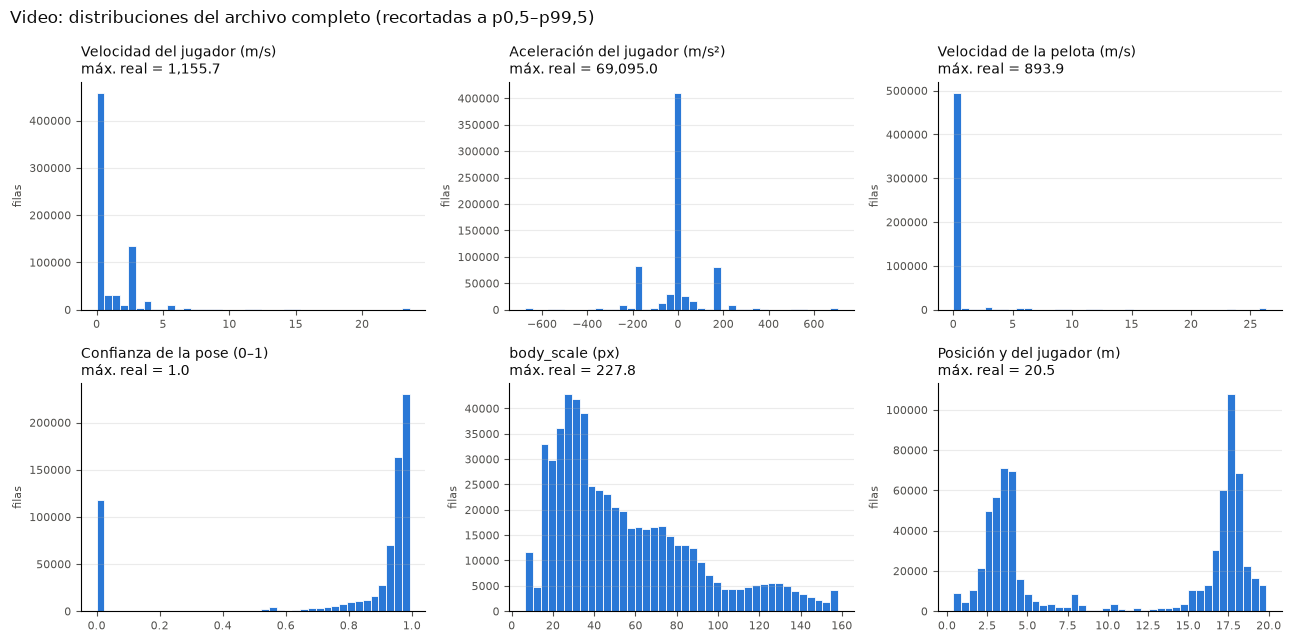

In [5]:
import matplotlib.pyplot as plt

VARIABLES_DIST = {
    'player_speed_mps': 'Velocidad del jugador (m/s)',
    'player_acceleration_mps2': 'Aceleración del jugador (m/s²)',
    'ball_speed_mps': 'Velocidad de la pelota (m/s)',
    'pose_confidence': 'Confianza de la pose (0–1)',
    'body_scale': 'body_scale (px)',
    'player_position_y': 'Posición y del jugador (m)',
}
dist = datos.leer_video(list(VARIABLES_DIST))
display(dist[list(VARIABLES_DIST)].describe(percentiles=[.01, .5, .99]).T.round(2))

COLOR, TINTA, TINTA_2 = '#2a78d6', '#0b0b0b', '#52514e'
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for eje, (col, titulo) in zip(ejes.flat, VARIABLES_DIST.items()):
    serie = dist[col].dropna()
    lo, hi = serie.quantile([0.005, 0.995])
    eje.hist(serie.clip(lo, hi), bins=40, color=COLOR, edgecolor='white', linewidth=0.6)
    eje.set_title(f'{titulo}\nmáx. real = {serie.max():,.1f}', fontsize=10, color=TINTA, loc='left')
    eje.tick_params(colors=TINTA_2, labelsize=8)
    eje.grid(axis='y', alpha=0.25)
    eje.spines[['top', 'right']].set_visible(False)
    eje.set_ylabel('filas', fontsize=8, color=TINTA_2)
fig.suptitle('Video: distribuciones del archivo completo (recortadas a p0,5–p99,5)', fontsize=12, color=TINTA, x=0.01, ha='left')
fig.tight_layout()
plt.show()

**Lectura**
- **Velocidad y aceleración del jugador:** son imposibles para una persona (máximos de 1.155,7 m/s y ±69.000 m/s²). El histograma muestra escalones discretos en 0, ~1,5 y ~3 m/s: es la cuantización de las posiciones (~5 cm) derivada frame a frame sin suavizar. Por eso se recalculan sobre la trayectoria suavizada (sección 1.8).
- **Velocidad de la pelota:** su mediana es 0 y su máximo 893,9 m/s; no sirve.
- **Confianza de la pose:** tiene un pico en 0 (frames sin pose) y el resto se concentra cerca de 0,95.
- **`body_scale`:** va de 3 a 228 px y está sesgada a la derecha según la distancia a la cámara, así que todo lo que se mide en píxeles debe normalizarse.
- **Posición `y`:** es bimodal, con un pico por cada fondo de la cancha.

### 1.2.4 Traza y formulario: tipos, faltantes y frecuencias

Las dos fuentes pequeñas se leen completas. En el formulario se omiten de las frecuencias las respuestas abiertas y los datos personales.

TRAZA (ambas canchas)


columna,ID_PARTIDO,ID_PUNTO,PUNTO_EQUIPO_1,PUNTO_EQUIPO_2,MARCADOR,ID_JUGADOR_1_EQUIPO_1,Equipo1_Banda1,ID_JUGADOR_2_EQUIPO_1,Equipo1_Banda2,ID_JUGADOR_1_EQUIPO_2,Equipo2_Banda1,ID_JUGADOR_2_EQUIPO_2,Equipo2_Banda2,EQUIPO_1_POSICION,EQUIPO_2_POSICION,POSICION_JUGADOR_1_EQUIPO_1,POSICION_JUGADOR_2_EQUIPO_1,POSICION_JUGADOR_1_EQUIPO_2,POSICION_JUGADOR_2_EQUIPO_2,cancha
tipo,int64,int64,int64,int64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,int64
no_nulos,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283
faltantes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
pct_faltante,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
distintos,27,13,2,2,59,20,4,19,4,16,4,17,4,1,1,2,2,3,4,2


Puntos por partido:


ID_PARTIDO,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
cancha,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,13.0,13.0,10.0,10.0,NaN,11.0,NaN,11.0,8.0,NaN,NaN,9.0,NaN,NaN,8.0,NaN,12.0,NaN,9.0,NaN,12.0,11.0,NaN,NaN,7.0,10.0,10.0
2,NaN,NaN,NaN,NaN,10.0,NaN,11.0,NaN,NaN,10.0,13.0,NaN,10.0,11.0,NaN,13.0,NaN,10.0,NaN,7.0,NaN,NaN,12.0,12.0,NaN,NaN,NaN


EQUIPO_1_POSICION: {'BOTTOM': 283}
POSICION_JUGADOR_1_EQUIPO_1: {'RIGHT': 163, 'LEFT': 120}
POSICION_JUGADOR_2_EQUIPO_2: {'RIGHT': 150, 'LEFT': 121, 'RIGTH': 12}
Equipo1_Banda1: {'Light_Blue': 98, 'Yellow': 97, 'Orange': 66, 'Dark_Blue': 22}

FORMULARIO


,tipo,no_nulos,faltantes,pct_faltante,distintos
columna,,,,,
RITMO_CARDIACO,object,12,17,58.62,12
COMENTARIOS,str,28,1,3.45,24
Puntos_Total,float64,27,2,6.90,21
Partidos_Jugados,float64,27,2,6.90,5
Puntos_Por_Partido,float64,27,2,6.90,24


,count,mean,std,min,25%,50%,75%,max
EDAD,29.0,20.3,2.9,18.0,19.0,19.0,21.0,30.0
SEMESTRE,29.0,5.0,2.0,3.0,4.0,4.0,6.0,10.0
ESTATURA,29.0,171.8,11.9,150.0,165.0,173.0,179.0,194.0
TALLA,29.0,69.1,16.7,40.0,60.0,69.0,80.0,107.0
Puntos_Total,27.0,19.1,9.1,2.0,13.0,19.0,23.5,41.0
Partidos_Jugados,27.0,5.1,1.2,2.0,4.5,5.0,6.0,7.0
Puntos_Por_Partido,27.0,3.6,1.4,0.5,3.1,3.8,4.6,5.9


GENERO: {'Masculino': 18, 'Femenino': 11}
EXPERIENCIA_PADEL: {'No': 16, 'Sí': 13}
TIEMPO_JUGANDO_PADEL: {'Menos de 6 meses': 22, 'Entre 6 meses y 1 año': 5, 'Más de 1 año': 2}
PRACTICA_OTRO_DEPORTE_RAQUETA: {'No': 14, 'Tenis': 9, 'Tenis de mesa': 3, 'Squash': 2, 'Otro': 1}
NIVEL_ACTUAL_PADEL: {'Principiante': 12, 'Primera vez': 11, 'Intermedio': 5, 'Avanzado': 1}
ESTADO_FISICO: {'Bueno': 19, 'Excelente': 5, 'Regular': 4, 'Malo': 1}
FRECUENCIA_DEPORTE: {'Más de 4 veces': 9, '1-2 veces': 9, '3-4 veces': 7, '0 veces': 3, 'No practico deportes': 1}
MANO_DOMINANTE: {'Derecha': 27, 'Izquierda': 2}
LESIONES_LY: {'No': 22, 'Sí': 7}


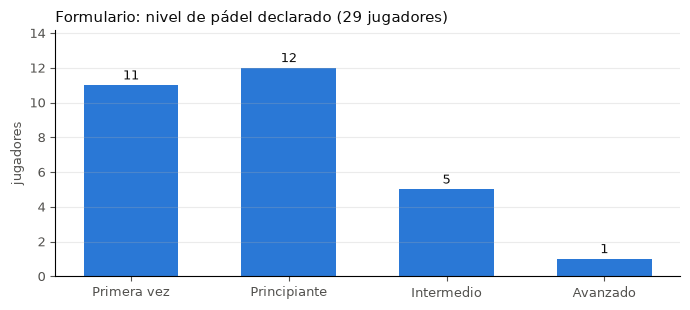

In [6]:
print('TRAZA (ambas canchas)')
display(datos.perfil_columnas(traza_cruda).T)
print('Puntos por partido:')
display(traza_cruda.groupby(['cancha', 'ID_PARTIDO']).size().rename('puntos').unstack(0).T)
for c in ['EQUIPO_1_POSICION', 'POSICION_JUGADOR_1_EQUIPO_1', 'POSICION_JUGADOR_2_EQUIPO_2', 'Equipo1_Banda1']:
    print(f'{c}:', traza_cruda[c].astype(str).str.strip().value_counts().to_dict())

print('\nFORMULARIO')
perfil_form = datos.perfil_columnas(form_crudo)
display(perfil_form[perfil_form['faltantes'] > 0])
display(form_crudo.select_dtypes('number').drop(columns=['CODIGO_ESTUDIANTE']).describe().T.round(1))
for c in ['GENERO', 'EXPERIENCIA_PADEL', 'TIEMPO_JUGANDO_PADEL', 'PRACTICA_OTRO_DEPORTE_RAQUETA', 'NIVEL_ACTUAL_PADEL',
          'ESTADO_FISICO', 'FRECUENCIA_DEPORTE', 'MANO_DOMINANTE', 'LESIONES_LY']:
    print(f'{c}:', form_crudo[c].value_counts(dropna=False).to_dict())

orden_nivel = ['Primera vez', 'Principiante', 'Intermedio', 'Avanzado']
nivel = form_crudo['NIVEL_ACTUAL_PADEL'].value_counts().reindex(orden_nivel, fill_value=0)
fig, eje = plt.subplots(figsize=(7, 3.2))
barras = eje.bar(nivel.index, nivel.values, color=COLOR, width=0.6)
eje.bar_label(barras, padding=2, fontsize=9, color=TINTA)
eje.set_ylim(0, nivel.max() * 1.18)
eje.set_title('Formulario: nivel de pádel declarado (29 jugadores)', fontsize=11, color=TINTA, loc='left')
eje.set_ylabel('jugadores', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=9)
eje.grid(axis='y', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Lectura**
- **Traza:** no tiene faltantes. El equipo 1 siempre está en BOTTOM y los lados aparecen con la errata `RIGTH`. Cada partido tiene entre 7 y 13 puntos.
- **Formulario:** solo tiene faltantes en `RITMO_CARDIACO` (descartada), `COMENTARIOS` y las 3 columnas de resultados (2 jugadores sin partidos). A diferencia de la versión CSV que leían los notebooks de entendimiento, en el Excel no aparece `#N/D` ni hay filas vacías de exportación.
- **Nivel:** el 79 % de los jugadores es principiante o juega por primera vez.
- **Mano:** solo hay 2 zurdos.

### 1.2.5 Relación entre las fuentes: nombres y llaves sin corregir

Antes de construir la tabla de equivalencias (1.3) se mide cuánto coinciden las fuentes tal como vienen: nombres exactos tras quitar tildes, espacios y mayúsculas, y la llave `(partido, punto)` del video contra `(ID_PARTIDO, ID_PUNTO)` de la traza.

In [7]:
nombres_form = set(form_crudo['NOMBRE'].map(idn.normalizar_nombre)) - {''}
nombres_traza_n = set(pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
                      .map(idn.normalizar_nombre)) - {''}
nombres_video_n = {idn.normalizar_nombre(n) for n in video['nombre_norm'].unique() if not idn.es_generico(n)}
display(pd.DataFrame([
    {'comparación': a, 'distintos_A': len(x), 'distintos_B': len(y), 'coincidencias_exactas': len(x & y)}
    for a, x, y in [('traza vs video', nombres_traza_n, nombres_video_n),
                    ('traza vs formulario', nombres_traza_n, nombres_form),
                    ('video vs formulario', nombres_video_n, nombres_form)]
]))
print('Nombres de la traza sin coincidencia exacta en el formulario:', sorted(nombres_traza_n - nombres_form))

llaves_video = set(map(tuple, video[['partido', 'punto']].drop_duplicates().to_numpy()))
llaves_traza = set(map(tuple, traza_cruda[['ID_PARTIDO', 'ID_PUNTO']].to_numpy()))
print(f'Llaves (partido, punto): video {len(llaves_video)} | traza {len(llaves_traza)} | en ambas {len(llaves_video & llaves_traza)}')
print('En el video y no en la traza:', sorted((int(a), int(b)) for a, b in llaves_video - llaves_traza))

,comparación,distintos_A,distintos_B,coincidencias_exactas
0,traza vs video,30,30,30
1,traza vs formulario,30,29,19
2,video vs formulario,30,29,19


Nombres de la traza sin coincidencia exacta en el formulario: ['alejandra briget deza cespedes', 'angie vanessa gonzalez farfan', 'isabella arenas', 'jose fabian garcia', 'juan andres ordonez vanegas', 'juan pablo vanegas herrera', 'laura sofia rodriguez gonzalez', 'miguel medina', 'nikol sofia avendano suarez', 'sofia santander', 'valentina rodriguez']
Llaves (partido, punto): video 272 | traza 283 | en ambas 268
En el video y no en la traza: [(7, 11), (11, 12), (23, 9), (32, 13)]


**Lectura**
- **Traza contra video:** los nombres coinciden 30 de 30, pero eso no garantiza que cada etiqueta esté en el jugador correcto; la sección 1.7 encuentra los partidos 8, 17 y 34 mal etiquetados.
- **Traza contra formulario:** solo coinciden 19 nombres. Ocho jugadores tienen variantes de nombre y 3 no llenaron el formulario; se resuelve en 1.3.
- **Llaves:** 268 puntos están en ambas fuentes.

### 1.2.6 Preguntas iniciales y su respuesta

Los notebooks de entendimiento cerraban con estas preguntas. Esta tabla las responde con lo encontrado en el resto de la Fase 1.

| Pregunta | Respuesta | Dónde |
|---|---|---|
| ¿Qué representa cada fila? | Video: un jugador en un frame. Traza: un punto. Formulario: un jugador. No hay filas repetidas en la llave del video. | 1.2.2 |
| ¿En qué sistema de coordenadas están las posiciones y en qué unidad? | Metros, por homografía a la cancha: `x` ∈ [0, 10], `y` ∈ [0, 20] y red en `y = 10`. BOTTOM está en `y > 10` y RIGHT en `x > 5` para ambos equipos (D13). Excepción: en el partido 17 la `y` es igual a `x` en todas las filas. | 1.6, 1.7 |
| ¿Cómo se codifican los booleanos y los indicadores de implausibilidad? | Como texto `True`/`False`. Los `*_implausible` solo existen en los partidos 10, 13 y 39; se descartan. | 1.2.2 |
| ¿Hay identificadores que separen partido, punto, jugador y video sin ambigüedad? | Track = `(partido, punto, player_id)`; jugador = `codigo` de 6 dígitos (D8). El nombre nunca es llave. | 1.3, 1.7 |
| ¿Sirven los nombres para unir las fuentes? | Solo a través de la tabla de equivalencias (D9). Video y traza coinciden en el texto, pero 3 partidos tienen etiquetas incorrectas (D12). | 1.3, 1.7 |
| ¿Cómo se construyen `partido` y `punto` y coinciden con la traza? | Son los mismos números de la traza: 268 puntos coinciden. 4 videos no tienen traza (D15) y 15 puntos de la traza no tienen video. El equipo confirmó que la numeración coincide. | 1.2.5, 1.7 |
| ¿Cómo tratar `#N/D`, faltantes, filas implausibles y pose ausente? | El Excel actual no tiene `#N/D`. Los faltantes del formulario se imputan (D4) y los de pose se interpolan en huecos de ≤5 frames. | 1.5, 1.8 |
| ¿En qué zona horaria está el formulario? | No importa: `Marca temporal` no se usa. | 1.5 |

### 1.2.7 Pelota: evidencia para descartarla

**Objetivo:** justificar con datos la decisión de no usar ninguna variable de la pelota.

**Qué significa que la posición de la pelota esté interpolada.** El pipeline de visión solo detecta la pelota en algunos frames. Para los demás no deja un faltante, sino que «rellena» la posición:
- entre dos detecciones traza una línea recta, de modo que la pelota avanza la misma distancia en cada frame (segunda diferencia igual a 0);
- antes de la primera detección y después de la última, repite la misma posición, de modo que la pelota aparece quieta.

Esas posiciones no son mediciones. Por eso `ball_speed_mps`, que se calcula frame a frame a partir de ellas, vale 0 cuando la pelota está «quieta» y da saltos imposibles (hasta 894 m/s) al pasar de un tramo inventado a una detección real. La celda clasifica cada frame según esas dos firmas y revisa si `player_hits_ball` coincide con un golpe real de raqueta.

,frames,pct
quieta (relleno),91925,50.5
posible detección,71543,39.3
tramo recto (interpolada),18417,10.1


,medida,valor
0,filas con player_hits_ball,2264.00
1,partidos con algún golpe,26.00
2,distancia mediana jugador–pelota en golpes (m),0.15
3,distancia mediana jugador–pelota en el resto (m),7.81
4,% de golpes con pico de raqueta (top 5 %) a ±5...,40.60
5,% de frames cualesquiera con pico a ±5 frames ...,21.60


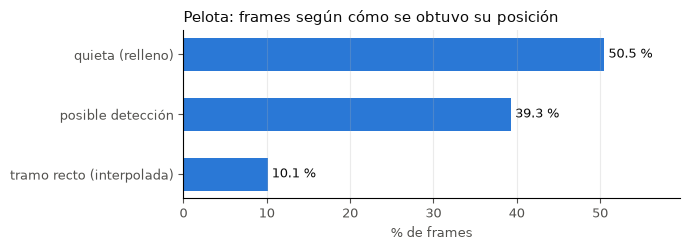

In [8]:
pelota = datos.leer_video(vid.COLUMNAS_PELOTA)
clases_pelota = vid.clasificar_frames_pelota(pelota)
display(clases_pelota)
display(vid.golpes_frente_a_picos(pelota))

fig, eje = plt.subplots(figsize=(7, 2.6))
orden_clases = clases_pelota.sort_values('pct')
barras = eje.barh(orden_clases.index, orden_clases['pct'], color=COLOR, height=0.55)
eje.bar_label(barras, labels=[f'{p:.1f} %' for p in orden_clases['pct']], padding=3, fontsize=9, color=TINTA)
eje.set_xlim(0, orden_clases['pct'].max() * 1.18)
eje.set_title('Pelota: frames según cómo se obtuvo su posición', fontsize=11, color=TINTA, loc='left')
eje.set_xlabel('% de frames', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=9)
eje.grid(axis='x', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
del pelota

**Lectura y decisión (D24)**
- **Posiciones:** el 50,5 % de los frames tiene la pelota quieta (relleno) y otro 10,1 % está en un tramo perfectamente recto (interpolación lineal). Cerca del 61 % de las posiciones no son detecciones reales, y en el 39 % restante no se puede saber cuáles lo son.
- **`player_hits_ball`:** se activa cuando la pelota está a ~0,15 m del jugador (frente a 7,8 m en el resto de frames). Es decir, se deriva de esa misma posición inventada.
- **Coincidencia con golpes reales:** solo el 41 % de esos «golpes» tiene un pico de velocidad de raqueta a ±5 frames, frente a un 22 % que se daría al azar.
- **Decisión:** se descartan todas las variables de la pelota, incluida `player_hits_ball`. Los golpes se aproximan con picos de la velocidad de raqueta normalizada por `body_scale`, que se mide sobre el jugador y no depende de la pelota (sección 1.8).

### 1.2.8 Atípicos y faltantes de las variables físicas

**Objetivo:** revisar que velocidad, aceleración, velocidad de raqueta y velocidades angulares estén en rangos posibles para una persona que juega pádel. Aquí solo se diagnostica; la corrección se aplica en la limpieza (1.8). No existe una variable de «fuerza» en los datos.

**Decisión D23: límites**

| Variable | Límite | Criterio |
|---|---|---|
| Velocidad del jugador | 8 m/s | Físico: por encima de lo que alcanza un jugador de pádel |
| Aceleración del jugador | 10 m/s² | Físico |
| Velocidades angulares (codo y raqueta) | 3.000 °/s | Físico |
| Velocidades en píxeles (raqueta, muñeca y codo) ÷ `body_scale` | Percentil 99,5 de cada jugador | Estadístico: no tienen unidad física directa |

- **Tratamiento:** el valor fuera de límite pasa a NaN; si el hueco es de ≤5 frames se interpola y, si es más largo, queda NaN. Se guarda el % de frames corregidos por jugador y punto.
- La velocidad y la aceleración se evalúan sobre la trayectoria suavizada (media móvil de 0,5 s), porque las columnas originales son ruido de cuantización.

In [9]:
fisicas = datos.leer_video(vid.COLUMNAS_ATIPICOS)
atipicos = vid.diagnosticar_atipicos(fisicas)
display(atipicos)
del fisicas

,variable,criterio,limite,pct_faltante,p50,p99,max,pct_sobre_limite
0,player_speed_mps (cruda),físico,8.0,0.2,0.00,11.37,1155.7,1.64
1,player_acceleration_mps2 (cruda),físico,10.0,0.3,1.85,702.44,69095.0,44.64
2,velocidad suavizada 0.5 s,físico,8.0,0.2,0.37,7.10,38.3,0.76
3,aceleración suavizada 0.5 s,físico,10.0,0.3,0.31,11.92,75.9,1.45
4,elbow_angular_velocity (°/s),físico,3000.0,22.4,67.63,1623.07,10477.6,0.20
5,racket_angular_velocity (°/s),físico,3000.0,23.6,79.15,3097.08,10788.0,1.05
6,vel_raqueta_norm (racket_speed / body_scale),"percentil 99,5 (global; por jugador en 1.8)",73.0,24.1,2.76,51.85,2486.5,0.50
7,vel_muneca_norm (wrist_speed / body_scale),"percentil 99,5 (global; por jugador en 1.8)",43.4,23.0,1.81,31.00,2336.0,0.50
8,vel_codo_norm (elbow_speed / body_scale),"percentil 99,5 (global; por jugador en 1.8)",36.4,21.8,1.73,27.06,2253.1,0.50


**Lectura**
- **Velocidad y aceleración crudas:** son inservibles. La aceleración supera 10 m/s² en el 45 % de las filas y llega a 69.095 m/s²; la velocidad supera 8 m/s en el 1,6 % y llega a 1.156 m/s.
- **Tras suavizar 0,5 s:** solo el 0,8 % de las velocidades y el 1,5 % de las aceleraciones quedan fuera de límite, y su mediana (0,37 m/s) es la de un jugador que se desplaza poco entre golpes. Lo que queda fuera son saltos del tracking (hasta 38 m/s), que la limpieza corrige.
- **Velocidades angulares:** superan 3.000 °/s en el 0,2 % (codo) y el 1,1 % (raqueta) de los frames con pose.
- **Velocidades en píxeles normalizadas:** tienen colas enormes (máximos de más de 2.000 cuerpos/s, frente a un p99 de 27–52), que corresponden a saltos de los puntos de pose.
- **Faltantes:** las variables de pose y raqueta faltan en el 22–24 % de las filas, igual que la pose en general (1.2.2).

### 1.2.9 Resumen de hallazgos y su tratamiento

| Tema | Hallazgo | Tratamiento |
|---|---|---|
| Grano | Una fila es un jugador en un frame; no hay duplicados en la llave. | Base del pipeline |
| fps | Variable por video: 24, 30 y 60 fps (algunos 59,9). El partido 32 tiene 300 frames por punto con fps de 11,8 a 39,9. | fps = 1/`duration` por punto (D2) |
| Velocidad y aceleración | Muy ruidosas, con máximos imposibles; la aceleración cruda supera 10 m/s² en el 45 % de las filas. | Límites físicos (D23) y recálculo sobre la trayectoria suavizada (1.8) |
| Pose y raqueta | Cerca del 20 % de faltantes; según el partido va de 0 % a 100 %. | Interpolar huecos de ≤5 frames y guardar `pose_coverage` (1.8) |
| Pelota | ~61 % de los frames son relleno o interpolación; `player_hits_ball` depende de esa posición. | Se descarta toda la familia (D24); golpes = picos de velocidad de raqueta |
| `team` | 8,3 % de faltantes; 100 % en los partidos 8 y 34. | Completar con el valor del jugador (1.8) |
| `*_implausible` | Solo en los partidos 10, 13 y 39. | No se usan |
| Atípicos físicos | Saltos del tracking y de la pose fuera de los límites humanos. | NaN y reconstrucción en huecos ≤5 frames (D23, 1.8) |
| Nombres | Coinciden entre traza y video, pero no con el formulario. | Tabla de equivalencias (1.3) e identidad por track (1.7) |
| Formulario | 29 filas; 3 jugadores sin formulario y 2 personas que no juegan. | Imputación (1.5) |

## 1.3 Identidad de los jugadores: códigos y nombres

**Objetivo:** una tabla única de equivalencias que lleve cualquier nombre de cualquier fuente a su nombre canónico y a su `codigo`.

**Decisiones**
- **D4 (códigos):** el equipo entregó los códigos de quienes no llenaron el formulario: Alejandra Briget Deza Céspedes (407710), Juan Pablo Vanegas Herrera (356629) y Laura Sofía Rodríguez González (324764).
- **D8:** todos los códigos tienen 6 dígitos. Jorge García pasa de 99999 a `099999` (se antepone un 0) y José Fabián García Camargo pasa de 1075684546 a `107568` (primeros 6 dígitos). El código se guarda como texto para conservar el cero inicial.
- **D9:** las variantes de nombre son el mismo jugador (no se separan en seguras y dudosas). Se usa el nombre completo con dos apellidos cuando alguna fuente lo tiene. Ejemplos: `Isabella Arenas` → *Isabella Arenas González* y `Sofia Santander` → *Ana Sofía Santander Prieto*.
- **Proceso recurrente (Teams):** si un nombre queda sin cruzar, se lista aquí para buscarlo en Teams; luego se agrega a `NOMBRES_CANONICOS` en `src/identidades.py` y se vuelve a correr.

In [10]:
codigos = idn.tabla_codigos(form_crudo)
nombres_traza = pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
equivalencias = idn.tabla_equivalencias(
    {'formulario': form_crudo['NOMBRE'], 'traza': nombres_traza, 'video': video['nombre_norm'].unique()}, codigos)

print('Códigos corregidos (D8):')
display(form_crudo.loc[form_crudo['CODIGO_ESTUDIANTE'].astype(str).isin(idn.CORRECCIONES_CODIGO), ['NOMBRE', 'CODIGO_ESTUDIANTE']]
        .assign(codigo=lambda d: d['CODIGO_ESTUDIANTE'].map(idn.normalizar_codigo)))
print('Cruces por alias (variantes del mismo nombre, D9):')
display(equivalencias[equivalencias['tipo_cruce'] == 'alias'])

resumen_cruce = equivalencias.pivot_table(index='fuente', columns='tipo_cruce', values='nombre_original', aggfunc='count', fill_value=0)
display(resumen_cruce)
pendientes_teams = idn.sin_cruzar(equivalencias)
print(f'Nombres sin cruzar (buscar en Teams): {len(pendientes_teams)}')
display(pendientes_teams)
print('Nombres canónicos con un solo apellido (ninguna fuente trae el nombre completo):')
print([n for n in codigos['nombre'] if len(n.split()) == 2])
datos.guardar_tabla(equivalencias, 'equivalencias_nombres')

Códigos corregidos (D8):


,NOMBRE,CODIGO_ESTUDIANTE,codigo
12,Jorge Garcia,99999,099999
13,Jose Fabian Garcia Camargo,1075684546,107568


Cruces por alias (variantes del mismo nombre, D9):


,fuente,nombre_original,nombre,tipo_cruce,codigo
6,traza,Sofia Santander,Ana Sofía Santander Prieto,alias,326450
7,video,sofia santander,Ana Sofía Santander Prieto,alias,326450
14,formulario,Angie vanessa gonzalez 0,Angie Vanessa González Farfan,alias,350977
33,traza,Isabella Arenas,Isabella Arenas González,alias,350430
34,video,isabella arenas,Isabella Arenas González,alias,350430
45,traza,Jose Fabian Garcia,Jose Fabian Garcia Camargo,alias,107568
46,video,jose fabian garcia,Jose Fabian Garcia Camargo,alias,107568
47,formulario,Juan Andrés Ordóñez,Juan Andrés Ordóñez Vanegas,alias,196393
75,traza,Miguel Medina,Miguel Medina Velez,alias,351752
76,video,miguel medina,Miguel Medina Velez,alias,351752


tipo_cruce,alias,exacto
fuente,,
formulario,3,26
traza,5,25
video,5,25


Nombres sin cruzar (buscar en Teams): 0


,fuente,nombre_original,nombre,tipo_cruce,codigo


Nombres canónicos con un solo apellido (ninguna fuente trae el nombre completo):
['Jeronimo Coy', 'Jorge García', 'Juliana Gómez', 'Marcela Velásquez', 'Miguel Delgado']


WindowsPath('D:/Miguel Delgado/universidad/2026-2/Analitica de Datos/analitica v2/Proyecto Final/Proyecto_final_analitica/data/interim/equivalencias_nombres.csv')

**Resultado**
- Hay 32 personas con código: los 29 del formulario y los 3 de la D4. De ellas, 30 juegan en la traza.
- Ningún nombre de ninguna fuente queda sin cruzar, así que hoy no hay pendientes para Teams. Ocho jugadores tienen variantes de nombre, que suman 13 nombres cruzados por alias.
- Cinco jugadores tienen un solo apellido en todas las fuentes (por ejemplo, Juliana Gómez y Miguel Delgado). Se mantienen así; si se quiere el segundo apellido, hay que buscarlo en Teams.
- Salida: `data/interim/equivalencias_nombres.csv`.

## 1.4 Traza de partidos

**Objetivo:** dejar la traza limpia por punto, con los códigos de los cuatro jugadores, y su versión larga jugador × punto (`participaciones`).

**Decisiones**
- **D3:** la variable objetivo es el ganador del punto, `PUNTO_EQUIPO_1`.
- **D13:** se corrige la errata `RIGTH` → `RIGHT` (partido 34). La convención de lados se verificó contra el video (sección 1.7): `BOTTOM` está en `y > 10` y, para ambos equipos, `RIGHT` está en `x > 5`.
- **Lado de cancha:** el equipo 1 siempre está en BOTTOM. Se incluye como variable de control, sin sacar conclusiones fuertes.

In [11]:
print('Controles de consistencia sobre la traza cruda:')
display(fuentes.validar_traza(traza_cruda))
lados_crudos = pd.concat([traza_cruda[f'POSICION_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS]).str.strip().value_counts()
print('Valores de lado en la traza cruda:', lados_crudos.to_dict())

traza = fuentes.limpiar_traza(traza_cruda, codigos)
participaciones = fuentes.traza_larga(traza)
puntos_traza = fuentes.tabla_puntos_traza(traza)
display(datos.comparar(datos.resumen_tabla(traza_cruda, 'traza cruda'), datos.resumen_tabla(traza, 'traza limpia'),
                       datos.resumen_tabla(participaciones, 'participaciones (jugador × punto)')))
assert participaciones['codigo'].notna().all()

finales = traza.groupby('ID_PARTIDO').agg(cancha=('cancha', 'first'), puntos=('ID_PUNTO', 'size'), marcador_final=('MARCADOR', 'last'))
print('Todos los partidos terminan cuando un equipo llega a 7:',
      finales['marcador_final'].str.split('-').map(lambda m: max(map(int, m)) == 7).all())
display(finales.T)

print(f"Balance de la variable objetivo: el equipo 1 gana el {traza['PUNTO_EQUIPO_1'].mean():.1%} de {len(traza)} puntos")
sin_traza = sorted(set(programacion['Partido']) - set(traza['ID_PARTIDO']))
print(f'Partidos programados sin traza ({len(sin_traza)}): {sin_traza}')

Controles de consistencia sobre la traza cruda:


,filas con problema
PUNTO_EQUIPO_1 + PUNTO_EQUIPO_2 != 1,0
partido-punto duplicado,0
MARCADOR distinto del acumulado,0
ID_PUNTO no consecutivo,0
lado LEFT/RIGHT cambia dentro del partido,0


Valores de lado en la traza cruda: {'LEFT': 566, 'RIGHT': 554, 'RIGTH': 12}


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,traza cruda,283,20,0,0.0
1,traza limpia,283,28,0,0.0
2,participaciones (jugador × punto),1132,12,0,0.0


Todos los partidos terminan cuando un equipo llega a 7: True


ID_PARTIDO,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
cancha,1,1,1,1,2,1,2,1,1,2,2,1,2,2,1,2,1,2,1,2,1,1,2,2,1,1,1
puntos,13,13,10,10,10,11,11,11,8,10,13,9,10,11,8,13,12,10,9,7,12,11,12,12,7,10,10
marcador_final,6-7,6-7,3-7,3-7,3-7,7-4,4-7,4-7,1-7,3-7,6-7,7-2,3-7,7-4,1-7,7-6,5-7,3-7,7-2,0-7,7-5,7-4,7-5,5-7,0-7,7-3,3-7


Balance de la variable objetivo: el equipo 1 gana el 43.1% de 283 puntos
Partidos programados sin traza (12): [2, 4, 6, 12, 15, 19, 21, 22, 30, 33, 36, 38]


**Resultado**
- La traza pasa todos los controles: un ganador por punto, sin duplicados, marcador igual al acumulado, puntos consecutivos y lados fijos dentro de cada partido.
- Todos los partidos terminan cuando un equipo llega a 7.
- El equipo 1 gana el 43,1 % de los puntos, así que las clases están moderadamente balanceadas.
- Los 12 partidos programados sin traza (2, 4, 6, 12, 15, 19, 21, 22, 30, 33, 36 y 38) no tienen tampoco video y no entran al análisis.

## 1.5 Formulario de jugadores

**Objetivo:** una fila por jugador con las variables fijas usables, codificadas, más los 3 jugadores imputados.

**Decisiones**
- **D1:** `TALLA` es el peso en kg. IMC = peso / (estatura en m)².
- **D4 (imputación):** los 3 jugadores sin formulario se imputan con datos de su mismo sexo.
  - Continuas (edad, estatura y peso): media. A las dos mujeres se les suma ruido N(0, sd de las mujeres) con semilla fija y se recorta al rango observado.
  - Ordinales: mediana; si cae entre dos categorías, se toma la inferior.
  - Categóricas: moda.
  - Las filas imputadas llevan `imputado = True`.
- **D5:** resuelta. La fila de 152 cm y 48 kg corresponde a Ana Catalina Suárez Caballero (código 337448) y ya viene con nombre en el formulario actual.
- **D11:** codificación ordinal (0 = menor):
  - nivel: Primera vez < Principiante < Intermedio < Avanzado.
  - tiempo jugando: <6 meses < 6–12 meses < >1 año.
  - experiencia: No < Sí.
  - estado físico: Malo < Regular < Bueno < Excelente.
  - frecuencia: 0 < 1–2 < 3–4 < >4 veces por semana.

  Como `TIEMPO_JUGANDO_PADEL` es categórica, se imputa como ordinal (mediana) y no con la media.
- **D10 (confirmada):** en `FRECUENCIA_DEPORTE`, las respuestas «0 veces» y «No practico deportes» se unen en el nivel 0.
- **`RITMO_CARDIACO`:** se descarta; tiene pocos datos (12 de 29) y no interesa para el análisis (confirmado por el equipo).
- **Descartadas:** ciudad, programa, semestre, razón y objetivo de participación, interés y clases de pádel, desayuno, género musical, comentarios y `RITMO_CARDIACO`.
- **Fuga de datos:** `Puntos_Total`, `Partidos_Jugados` y `Puntos_Por_Partido` no entran a la tabla; solo se usan abajo para validar la traza.

In [12]:
jugadores_base = fuentes.limpiar_formulario(form_crudo)
jugadores = fuentes.agregar_derivadas_jugadores(fuentes.imputar_sin_formulario(jugadores_base, datos.SEMILLA))
display(datos.comparar(datos.resumen_tabla(form_crudo, 'formulario crudo'),
                       datos.resumen_tabla(jugadores_base, 'formulario limpio'),
                       datos.resumen_tabla(jugadores, 'jugadores (con imputados y derivadas)')))

print('Jugadores imputados (D4):')
display(jugadores[jugadores['imputado']])
print('Rangos de las continuas:')
display(jugadores[['edad', 'estatura_cm', 'peso_kg', 'imc']].astype(float).describe().T.round(1))

juegan = set(participaciones['codigo'])
print(f'Jugadores de la traza con datos: {len(juegan & set(jugadores["codigo"]))} de {len(juegan)}')
print('En el formulario pero sin partidos con traza:', jugadores.loc[~jugadores['codigo'].isin(juegan), 'nombre'].tolist())
datos.guardar_tabla(jugadores, 'jugadores')

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,formulario crudo,29,30,24,2.76
1,formulario limpio,29,15,0,0.00
2,jugadores (con imputados y derivadas),32,20,0,0.00


Jugadores imputados (D4):


,codigo,nombre,genero,mujer,edad,estatura_cm,peso_kg,imc,mano_dominante,zurdo,nivel_padel,tiempo_jugando_padel,experiencia_padel,otro_deporte_raqueta,practica_otra_raqueta,estado_fisico,frecuencia_deporte,lesiones_ly,lesion_ultimo_anio,imputado
0,407710,Alejandra Briget Deza Céspedes,Femenino,1,19,162,40.0,15.24,Derecha,0,1,0,0,No,0,2,2,No,0,True
18,356629,Juan Pablo Vanegas Herrera,Masculino,0,20,179,76.8,23.97,Derecha,0,1,0,0,Tenis,1,2,2,No,0,True
22,324764,Laura Sofía Rodríguez González,Femenino,1,24,165,51.9,19.06,Derecha,0,1,0,0,No,0,2,2,No,0,True


Rangos de las continuas:


,count,mean,std,min,25%,50%,75%,max
edad,32.0,20.4,2.9,18.0,19.0,19.0,21.2,30.0
estatura_cm,32.0,171.5,11.6,150.0,164.5,173.0,179.0,194.0
peso_kg,32.0,67.9,17.0,40.0,55.5,68.5,80.0,107.0
imc,32.0,22.8,3.9,15.2,20.4,22.5,25.0,32.8


Jugadores de la traza con datos: 30 de 30
En el formulario pero sin partidos con traza: ['Juan Camilo Sánchez', 'Karol Valentina Carranza Gantiva']


WindowsPath('D:/Miguel Delgado/universidad/2026-2/Analitica de Datos/analitica v2/Proyecto Final/Proyecto_final_analitica/data/interim/jugadores.csv')

**Validación con las columnas de fuga.** Se recalcula desde la traza la suma de puntos que hizo el equipo de cada jugador en sus partidos y se compara con `Puntos_Total` y `Partidos_Jugados`. No entran a ningún modelo.

In [13]:
puntos_traza_jugador = (participaciones.groupby(['codigo', 'partido'])['gano_punto'].sum()
                        .groupby('codigo').agg(puntos_desde_traza='sum', partidos_con_traza='size'))
validacion = (form_crudo[['NOMBRE', 'Puntos_Total', 'Partidos_Jugados']]
              .assign(codigo=form_crudo['CODIGO_ESTUDIANTE'].map(idn.normalizar_codigo))
              .merge(puntos_traza_jugador, on='codigo', how='left'))
validacion['coincide_puntos'] = validacion['Puntos_Total'] == validacion['puntos_desde_traza']
validacion['coincide_partidos'] = validacion['Partidos_Jugados'] == validacion['partidos_con_traza']
con_dato = validacion['Puntos_Total'].notna()
print(f"Jugadores con Puntos_Total: {con_dato.sum()} | coincide con la traza: {validacion.loc[con_dato, 'coincide_puntos'].sum()}"
      f" | Partidos_Jugados coincide: {validacion.loc[con_dato, 'coincide_partidos'].sum()}")
print('Diferencias:')
display(validacion[con_dato & ~(validacion['coincide_puntos'] & validacion['coincide_partidos'])])

Jugadores con Puntos_Total: 27 | coincide con la traza: 27 | Partidos_Jugados coincide: 2
Diferencias:


,NOMBRE,Puntos_Total,Partidos_Jugados,codigo,puntos_desde_traza,partidos_con_traza,coincide_puntos,coincide_partidos
0,Ana Sofía Santander Prieto,4.0,5.0,326450,4.0,2.0,True,False
1,Andrés Felipe Santafe Buitrago,41.0,7.0,352369,41.0,6.0,True,False
2,Angel Santiago Toribio Godoy,27.0,6.0,349345,27.0,5.0,True,False
3,Angie vanessa gonzalez 0,22.0,6.0,350977,22.0,4.0,True,False
4,Antonio Benitez Rueda,24.0,7.0,334943,24.0,4.0,True,False
5,David Jeronimo Rojas Gutierrez,12.0,5.0,376184,12.0,4.0,True,False
6,David Neisa Tello,17.0,6.0,349342,17.0,4.0,True,False
7,Gabriel Armando González Sosa,25.0,5.0,323614,25.0,4.0,True,False
8,Gabriel López Acosta,20.0,5.0,367769,20.0,4.0,True,False
9,Isabella Arenas González,2.0,4.0,350430,2.0,2.0,True,False


**Resultado**
- La tabla de jugadores tiene 32 filas (29 del formulario más 3 imputados) y sus variables usables no tienen faltantes.
- Los 30 jugadores de la traza tienen datos. Juan Camilo Sánchez y Karol Carranza no juegan ningún partido con traza.
- **Validación:** `Puntos_Total` coincide con la traza en los 27 jugadores que tienen el dato, lo que confirma la traza y el cruce de códigos. En cambio, `Partidos_Jugados` es mayor que los partidos con traza: cuenta partidos programados sin traza que no aportan puntos al total.
- Salida: `data/interim/jugadores.csv`.

## 1.6 Video: diagnóstico de calidad por punto

**Objetivo:** detectar automáticamente, para cada punto de video, los problemas que afectan la limpieza y el modelado. La detección funciona igual para cualquier video nuevo.

**Decisiones**
- **D6:** los CSV de video se reciben ya generados; no se usa el pipeline de visión del profesor.
- **D7:** el punto 10 del partido 5 es una copia exacta del punto 9. Se conserva el video como punto 9 y el punto 10 queda sin video. La regla general es conservar el de menor número; cualquier duplicado nuevo se revisa con el equipo.
- **D26 y D30:** no hay tratamientos por partido; solo reglas generales y solo conclusiones que el código demuestra.
- Banderas que se calculan por punto:

| Bandera | Regla |
|---|---|
| `y_invalida` | `y` = `x` en más del 95 % de las filas |
| `sin_pose` | 0 % de frames con pose |
| `duplicado_de_punto` | firma idéntica a otro punto del mismo partido |

In [14]:
diagnostico = vid.diagnosticar_puntos(video)
banderas = ['y_invalida', 'sin_pose']
por_partido = diagnostico.groupby('partido').agg(
    puntos=('punto', 'size'), fps=('fps', 'median'), pct_pose_medio=('pct_pose', 'mean'),
    pct_team_faltante=('pct_team_faltante', 'mean'), pct_fuera_cancha=('pct_fuera_cancha', 'mean'),
    tracks_genericos=('tracks_genericos', 'sum'), duplicados=('duplicado_de_punto', 'count'),
    **{b: (b, 'sum') for b in banderas}).round(1)
display(por_partido)
print('Partidos con alguna bandera o duplicado:')
display(por_partido[(por_partido[banderas + ['duplicados']] > 0).any(axis=1)])

,puntos,fps,pct_pose_medio,pct_team_faltante,pct_fuera_cancha,tracks_genericos,duplicados,y_invalida,sin_pose
partido,,,,,,,,,
1,11,60.0,59.1,5.4,0.9,3,0,0,0
3,8,60.0,81.8,3.6,0.1,4,0,0,0
5,10,24.0,92.7,1.4,0.3,4,1,0,0
7,11,24.0,87.3,0.2,0.2,1,0,0,0
8,8,30.0,100.0,100.0,2.1,0,0,0,0
9,11,30.0,93.0,7.0,0.3,5,0,0,0
10,11,60.0,92.2,12.6,2.2,0,0,0,0
11,12,30.0,96.0,0.9,0.2,5,0,0,0
13,7,30.0,98.2,15.2,0.1,0,0,0,0


Partidos con alguna bandera o duplicado:


,puntos,fps,pct_pose_medio,pct_team_faltante,pct_fuera_cancha,tracks_genericos,duplicados,y_invalida,sin_pose
partido,,,,,,,,,
5,10,24.0,92.7,1.4,0.3,4,1,0,0
17,9,30.0,0.0,60.9,4.9,79,0,9,9


**Resultado: partidos con problemas de calidad**

| Partido | Problema | Consecuencia para el análisis |
|---|---|---|
| 5 | El punto 10 es una copia del punto 9 | El punto 10 queda sin video (D7) |
| 8 y 34 | Solo se detecta la pareja del fondo BOTTOM (cámara de media cancha) y `team` está vacío | No hay video del equipo 2: sus puntos quedan fuera del modelo pareja contra pareja (D20) |
| 17 | `y` es copia de `x` y no hay pose en ningún frame; las etiquetas son `Jugador 1–4` | Sin tratamiento especial (D26): la regla general de `y` inválida deja NaN su profundidad y su velocidad |

## 1.7 Video: cruce con la traza e identidad de cada track

**Objetivo:** asignar a cada track `(partido, punto, player_id)` el `codigo` del jugador, de acuerdo con la traza.

**Decisiones**
- **D12:** se confía en la etiqueta de nombre del video si en el partido al menos el 50 % de las filas tiene nombres de la alineación de la traza y al menos el 80 % concuerda con la casilla (fondo, lado) que indica la traza.
  - Si no se cumple, la identidad se asigna **por posición contra la traza**. Para el fondo se usa `team` (o `y > 10` cuando `team` falta) y para el lado `x > 5`.
  - Se asigna de forma codiciosa: cada casilla recibe el track con mayor filas × p(fondo) × p(lado).
- **D14:** los tracks genéricos (`Player_N`) y los que quedan sin casilla compatible se descartan de la identidad.
- **D15:** los 4 puntos de video sin traza (7-11, 11-12, 23-9 y 32-13) se excluyen, porque según la traza esos partidos ya habían terminado. El equipo confirmó que la numeración de puntos del video coincide con la de la traza.

In [15]:
tracks = vid.resumir_tracks(video, diagnostico)
metodo_partido = vid.concordancia_por_partido(tracks, participaciones, diagnostico)
print('Concordancia de las etiquetas de nombre con la traza, por partido:')
display(metodo_partido)

identidades = vid.asignar_identidades(tracks, participaciones, diagnostico, metodo_partido)
print('Tracks y filas por resultado de la asignación:')
display(identidades.groupby(['conservar', 'metodo', 'motivo'], dropna=False)
        .agg(tracks=('filas', 'size'), filas=('filas', 'sum')).reset_index())
etq = identidades[identidades['metodo'] == 'etiqueta']
print(f"Con método etiqueta, el {np.average(etq['concuerda_posicion'].astype(float), weights=etq['filas']):.1%} "
      'de las filas también concuerda con la posición de la traza.')

Concordancia de las etiquetas de nombre con la traza, por partido:


,partido,filas,pct_filas_en_alineacion,pct_concordancia_posicion,metodo
0,1,75217.0,99.8,100.0,etiqueta
1,3,54222.0,100.0,100.0,etiqueta
2,5,12734.0,98.6,100.0,etiqueta
3,7,9137.0,100.0,100.0,etiqueta
4,8,6850.0,0.0,NaN,posicion
5,9,15487.0,99.4,96.9,etiqueta
6,10,27762.0,100.0,100.0,etiqueta
7,11,13606.0,99.7,100.0,etiqueta
8,13,14089.0,100.0,100.0,etiqueta
9,14,33254.0,99.0,97.4,etiqueta


Tracks y filas por resultado de la asignación:


,conservar,metodo,motivo,tracks,filas
0,False,NaN,punto sin traza,16,4044
1,False,NaN,sin casilla libre compatible,47,3300
2,False,NaN,track genérico sin identidad,105,3772
3,False,NaN,video duplicado del punto 9,4,1932
4,True,etiqueta,NaN,952,673335
5,True,posicion,NaN,77,32553


Con método etiqueta, el 99.0% de las filas también concuerda con la posición de la traza.


**Partidos asignados por posición.** La tabla cruza la etiqueta original del video con la identidad asignada (número de puntos).

In [16]:
reasignados = identidades[identidades['conservar'] & (identidades['metodo'] == 'posicion')]
for p, g in reasignados.groupby('partido'):
    print(f'\nPartido {p}:')
    display(pd.crosstab(g['etiqueta_video'], g['nombre']))


Partido 8:


nombre,Angel Santiago Toribio Godoy,Mariana Alfonso Forero
etiqueta_video,,
david neisa tello,2,6
jose fabian garcia,6,2



Partido 17:


nombre,Isabella Arenas González,Jeronimo Coy,Juliana Gómez,Luis Felipe Cuellar Santamaria
etiqueta_video,,,,
jugador 1,0,0,9,0
jugador 2,9,0,0,0
jugador 3,0,9,0,0
jugador 4,0,0,0,9



Partido 34:


nombre,Alejandra Briget Deza Céspedes,David Neisa Tello,Jeronimo Coy,Jose Fabian Garcia Camargo
etiqueta_video,,,,
alejandra briget deza cespedes,0,2,0,0
david neisa tello,11,0,0,0
jeronimo coy,0,0,1,0
jose fabian garcia,0,0,0,11


**Tabla de puntos** (una fila por punto): une la traza y el video e indica el estado del video y cuántos jugadores quedaron identificados por equipo.

In [17]:
puntos = vid.tabla_puntos(puntos_traza, diagnostico, identidades)
participaciones = vid.enlazar_participaciones(participaciones, identidades)

display(datos.comparar(datos.resumen_tabla(puntos, 'puntos'), datos.resumen_tabla(participaciones, 'participaciones'),
                       datos.resumen_tabla(identidades, 'identidades_video')))
print('Estado del video por punto:', puntos['estado_video'].value_counts().to_dict())
disp = puntos[puntos['estado_video'] == 'disponible']
print('Puntos con video disponible por jugadores identificados (equipo 1 × equipo 2):')
display(pd.crosstab(disp['identificados_e1'], disp['identificados_e2']))

cobertura_partido = puntos[puntos['en_traza']].groupby('partido').agg(
    puntos_traza=('punto', 'size'), con_video=('estado_video', lambda s: (s == 'disponible').sum()),
    equipos_completos=('equipos_completos', 'sum'))
display(cobertura_partido.T)

for nombre, tabla in [('identidades_video', identidades), ('puntos', puntos), ('participaciones', participaciones)]:
    print('Guardado:', datos.guardar_tabla(tabla, nombre).relative_to(RAIZ))

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,puntos,287,29,494,5.94
1,participaciones,1132,15,206,1.21
2,identidades_video,1201,21,2312,9.17


Estado del video por punto: {'disponible': 267, 'sin video': 15, 'video sin traza': 4, 'duplicado': 1}
Puntos con video disponible por jugadores identificados (equipo 1 × equipo 2):


identificados_e2,0,1,2
identificados_e1,,,
2,16,7,244


partido,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
puntos_traza,13,13,10,10,10,11,11,11,8,10,13,9,10,11,8,13,12,10,9,7,12,11,12,12,7,10,10
con_video,11,8,9,10,8,11,11,11,7,9,11,9,10,10,8,13,12,10,9,7,12,11,12,11,7,10,10
equipos_completos,11,8,9,10,0,11,11,11,7,9,11,9,10,10,7,13,12,10,6,7,12,11,12,0,7,10,10


Guardado: data\interim\identidades_video.csv
Guardado: data\interim\puntos.csv
Guardado: data\interim\participaciones.csv


**Resultado**
- Las etiquetas de nombre son confiables en 24 de los 27 partidos: con ellas, el 99 % de las filas concuerda con la casilla de la traza.
- Los partidos 8, 17 y 34 se reasignan por posición:
  - **8:** el video tenía los nombres del partido 34. Los dos jugadores del fondo BOTTOM son Angel Toribio (RIGHT) y Mariana Alfonso (LEFT).
  - **17:** `Jugador 1–4` corresponden a Juliana Gómez (top-left), Isabella Arenas (top-right), Jerónimo Coy (bottom-left) y Luis Felipe Cuéllar (bottom-right).
  - **34:** el track etiquetado «David Neisa» está en BOTTOM-LEFT, así que es Alejandra Deza; los pocos frames del fondo TOP corresponden a David Neisa y Jerónimo Coy.
- De los 283 puntos de la traza, 267 tienen video disponible. En ellos, 1.029 de las 1.068 participaciones jugador × punto posibles tienen track.
- 244 puntos tienen los dos equipos completos, 16 solo tienen al equipo BOTTOM (partidos 8 y 34) y 7 tienen 2 + 1 jugadores.
- Salidas: `data/interim/identidades_video.csv`, `data/interim/puntos.csv` y `data/interim/participaciones.csv`.

## 1.8 Limpieza del video frame × jugador

**Objetivo:** una tabla limpia frame × jugador, solo con los tracks conservados en 1.7, con posiciones suavizadas, cinemática recalculada, atípicos corregidos, pose interpolada y las variables combinadas que usará la sección 1.9. Todo se aplica track por track con las mismas reglas para cualquier partido.

**Decisiones**
- **D24:** se descartan todas las columnas de la pelota, incluida `player_hits_ball` (evidencia en 1.2.7).
- **D29 (parámetros de la limpieza):**
  - **Fuera de la cancha:** las posiciones hasta 0,5 m afuera se recortan al borde; las más lejanas pasan a NaN.
  - **Suavizado:** media móvil centrada de 0,5 s sobre `x` e `y`. La velocidad y la aceleración se recalculan sobre la trayectoria suavizada, con el fps de cada punto (D2).
  - **Golpes:** máximos locales de la velocidad de raqueta normalizada por encima del percentil 90 del jugador en el punto, con al menos 0,4 s entre golpes.
  - **Rol:** el lado de la traza, fijo en el partido: drive si juega a la derecha (RIGHT) y revés si juega a la izquierda (LEFT). Además se mide si en cada frame está en su lado (`en_su_lado`).
- **D23 (atípicos, en dos pasadas):**
  1. Los frames con velocidad suavizada mayor que 8 m/s (saltos del tracking) pierden la posición, que se interpola si el hueco es de ≤5 frames.
  2. Se recalcula la cinemática; la velocidad mayor que 8 m/s o la aceleración mayor que 10 m/s² pasan a NaN y se reconstruyen igual.
  3. Las velocidades angulares mayores que 3.000 °/s y las velocidades en píxeles por encima del percentil 99,5 de cada jugador también pasan a NaN y se reconstruyen.
- **Pose:** las variables numéricas se interpolan en huecos de ≤5 frames; los indicadores booleanos no se interpolan. `pose_coverage` es el % de frames con pose detectada.
- **D25 (variables combinadas):**
  - `x` e `y` → `velocidad_mps`, `aceleracion_mps2` y `desplazamiento_m`.
  - Velocidades de raqueta, muñeca y codo ÷ `body_scale` → `indice_vel_golpe` (promedio de las tres, en cuerpos/s).
  - Raqueta sobre el hombro o muñeca sobre la cabeza → `juego_aereo`.
- **Faltantes menores:** `team` sale del fondo de la traza y la distancia al compañero se recalcula con las posiciones suavizadas.
- **Profundidad:** distancia a la red y sección descriptiva: red (< 3 m), transición (3–6,95 m) y fondo (≥ 6,95 m). El estilo (D21) usa la línea de saque (6,95 m).
- **D26:** ningún partido recibe tratamiento especial; solo se aplican reglas generales calculadas en el notebook. Por la regla de `y` inválida, en el partido 17 quedan NaN su `y`, su profundidad y su velocidad, y su pose falta.

Limpieza: 44 s


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,video crudo (tracks conservados),705888,25,2151858,12.19
1,video limpio (frame × jugador),705888,42,2388745,8.06


Rangos antes y después (valores absolutos):


,antes,después,antes_pct_faltante,antes_p50,antes_p99,antes_max,después_pct_faltante,después_p50,después_p99,después_max
0,player_position_x,x_m,0.0,4.67,8.95,11.8,0.6,4.72,8.86,10.0
1,player_position_y,y_m,0.0,14.63,19.61,20.5,3.6,15.43,19.63,20.0
2,player_speed_mps,velocidad_mps,0.1,0.00,10.68,1155.7,4.3,0.37,4.45,8.0
3,player_acceleration_mps2,aceleracion_mps2,0.3,1.74,701.24,69095.0,4.4,0.30,6.49,10.0
4,elbow_angular_velocity,vel_ang_codo_dps,22.0,67.50,1626.38,10477.6,20.2,68.38,1500.26,2999.2
5,racket_angular_velocity,vel_ang_raqueta_dps,23.1,78.91,3105.83,10788.0,21.3,79.67,1928.33,2999.6
6,racket_speed / body_scale,vel_raqueta_norm,23.6,2.76,51.87,2486.5,21.7,2.82,42.91,415.5


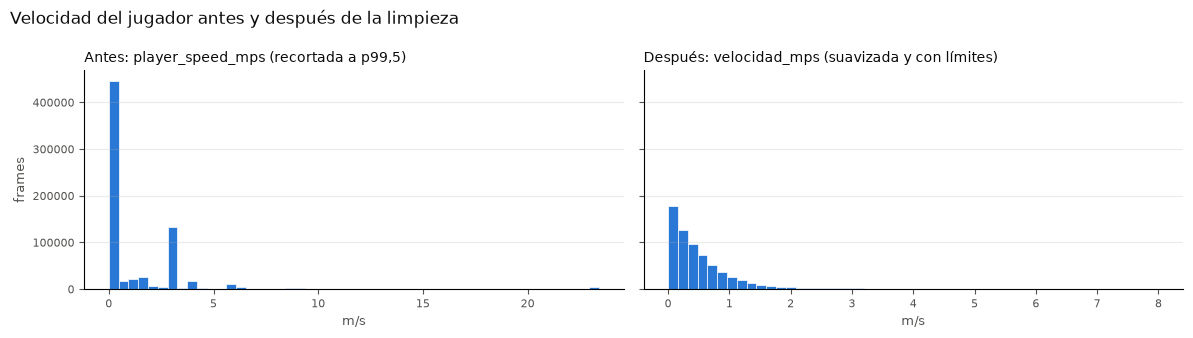

In [18]:
import time

t0 = time.time()
video_bruto = datos.leer_video(vid.COLUMNAS_LIMPIEZA + ['player_speed_mps', 'player_acceleration_mps2'])
conservados = video_bruto.merge(identidades.loc[identidades['conservar'], vid.LLAVE_TRACK], on=vid.LLAVE_TRACK)
video_limpio = vid.limpiar_video(video_bruto, identidades, diagnostico)
print(f'Limpieza: {time.time() - t0:.0f} s')
display(datos.comparar(datos.resumen_tabla(conservados, 'video crudo (tracks conservados)'),
                       datos.resumen_tabla(video_limpio, 'video limpio (frame × jugador)')))

def rango(serie):
    a = serie.astype(float).abs()
    return {'pct_faltante': round(100 * a.isna().mean(), 1), 'p50': round(a.median(), 2), 'p99': round(a.quantile(0.99), 2),
            'max': round(a.max(), 1)}

pares = [('player_position_x', 'x_m'), ('player_position_y', 'y_m'), ('player_speed_mps', 'velocidad_mps'),
         ('player_acceleration_mps2', 'aceleracion_mps2'), ('elbow_angular_velocity', 'vel_ang_codo_dps'),
         ('racket_angular_velocity', 'vel_ang_raqueta_dps')]
filas = [{'antes': a, 'después': d, **{f'antes_{k}': v for k, v in rango(conservados[a]).items()},
          **{f'después_{k}': v for k, v in rango(video_limpio[d]).items()}} for a, d in pares]
filas.append({'antes': 'racket_speed / body_scale', 'después': 'vel_raqueta_norm',
              **{f'antes_{k}': v for k, v in rango(conservados['racket_speed'] / conservados['body_scale']).items()},
              **{f'después_{k}': v for k, v in rango(video_limpio['vel_raqueta_norm']).items()}})
print('Rangos antes y después (valores absolutos):')
display(pd.DataFrame(filas))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
crudo = conservados['player_speed_mps'].dropna()
for eje, serie, titulo in [(ejes[0], crudo.clip(upper=crudo.quantile(0.995)), 'Antes: player_speed_mps (recortada a p99,5)'),
                           (ejes[1], video_limpio['velocidad_mps'].dropna(), 'Después: velocidad_mps (suavizada y con límites)')]:
    eje.hist(serie, bins=50, color=COLOR, edgecolor='white', linewidth=0.5)
    eje.set_title(titulo, fontsize=10, color=TINTA, loc='left')
    eje.set_xlabel('m/s', fontsize=9, color=TINTA_2)
    eje.tick_params(colors=TINTA_2, labelsize=8)
    eje.grid(axis='y', alpha=0.25)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_ylabel('frames', fontsize=9, color=TINTA_2)
fig.suptitle('Velocidad del jugador antes y después de la limpieza', fontsize=12, color=TINTA, x=0.01, ha='left')
fig.tight_layout()
plt.show()
del video_bruto, conservados

**Calidad por jugador × punto.** Se agrega a `participaciones` y se guardan las tablas.

In [19]:
calidad = vid.calidad_limpieza(video_limpio)
print('Calidad de la limpieza por jugador × punto:')
display(calidad.drop(columns=['partido', 'punto']).describe().T.round(1))

con_y = video_limpio['seccion'].notna()
print('Frames por sección de profundidad (con y válida):',
      (100 * video_limpio.loc[con_y, 'seccion'].value_counts(normalize=True)).round(1).to_dict())
print(f"Golpes detectados: {int(video_limpio['golpe'].sum()):,} | juego aéreo en el "
      f"{100 * video_limpio['juego_aereo'].astype('float').mean():.1f} % de los frames con pose")
print('Partido 17 (y inválida): % de frames sin velocidad =',
      round(100 * video_limpio.loc[video_limpio['partido'] == 17, 'velocidad_mps'].isna().mean(), 1))
print('Control con el punto 24-1:')
display(calidad.query('partido == 24 and punto == 1').merge(jugadores[['codigo', 'nombre']], on='codigo'))

participaciones = participaciones.drop(columns=[c for c in calidad.columns if c in participaciones.columns
                                                 and c not in ['partido', 'punto', 'codigo']])
participaciones = participaciones.merge(calidad.drop(columns='frames_video'), on=['partido', 'punto', 'codigo'], how='left')
print('Guardado:', datos.guardar_tabla(video_limpio, 'video_limpio', formato='parquet').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(participaciones, 'participaciones').relative_to(RAIZ))

Calidad de la limpieza por jugador × punto:


,count,mean,std,min,25%,50%,75%,max
frames_video,1029.0,686.0,577.9,1.0,305.0,522.0,821.0,4304.0
pose_coverage,1029.0,84.0,25.8,0.0,82.7,95.3,99.7,100.0
pct_posicion_corregida,1029.0,0.7,2.9,0.0,0.0,0.0,0.0,38.2
pct_cinematica_corregida,1029.0,0.6,2.2,0.0,0.0,0.0,0.0,18.0
pct_y_faltante,1029.0,4.5,19.4,0.0,0.0,0.0,0.0,100.0
golpes,1029.0,11.2,9.1,0.0,6.0,9.0,14.0,85.0


Frames por sección de profundidad (con y válida): {'fondo': 58.4, 'transicion': 39.9, 'red': 1.7}
Golpes detectados: 11,558 | juego aéreo en el 2.0 % de los frames con pose
Partido 17 (y inválida): % de frames sin velocidad = 100.0
Control con el punto 24-1:


,partido,punto,codigo,frames_video,pose_coverage,pct_posicion_corregida,pct_cinematica_corregida,pct_y_faltante,golpes,nombre
0,24,1,199884,1022,84.1,0.0,0.0,0.0,22,Juliana Gómez
1,24,1,283321,1022,95.4,0.0,0.0,0.0,14,Santiago Pujol Zabala
2,24,1,324764,1022,85.9,0.0,0.0,0.0,19,Laura Sofía Rodríguez González
3,24,1,352369,1002,26.6,0.0,0.0,0.0,3,Andrés Felipe Santafé Buitrago


Guardado: data\interim\video_limpio.parquet
Guardado: data\interim\participaciones.csv


**Resultado**
- **Tabla limpia:** 705.888 filas frame × jugador de los 1.029 tracks conservados, con 42 columnas. Se guardó en `data/interim/video_limpio.parquet`.
- **Velocidad:** tras la limpieza su mediana es 0,37 m/s y su máximo 8 m/s (antes, 1.156 m/s). La aceleración queda entre −10 y 10 m/s².
- **Corrección de atípicos:** en promedio se corrigió el 0,7 % de las posiciones y el 0,6 % de la cinemática por jugador × punto.
- **Pose:** la cobertura mediana es del 95 %. Control: Andrés Santafé tiene 26,6 % en el punto 24-1, como se había visto antes.
- **Golpes:** se detectaron 11.558, con una mediana de 9 por jugador y punto.
- **Profundidad:** los jugadores pasan el 58 % del tiempo en el fondo, el 40 % en transición y solo el 1,7 % en la red (distancia mediana a la red: 7,2 m). Por eso el estilo (D21) se define con la línea de saque: con una zona de red de 3 m casi ningún jugador saldría atacante.
- **Partido 17:** sin velocidad ni profundidad (regla general de `y` inválida); conserva `x`, lado y golpes.

## 1.9 Variables jugador × punto

**Objetivo:** describir el estilo de juego de cada jugador en cada punto a partir de `video_limpio`. Las variables se agregan a `participaciones` (jugador × punto) y el estilo fijo de cada jugador, a `jugadores`.

**Decisiones**
- **D21 (estilo):** la zona atacante es todo lo que está delante de la línea de saque (a menos de 6,95 m de la red). Un jugador es atacante (1) en un punto si pasa allí al menos tanto tiempo como detrás. El estilo del jugador es atacante si lo fue en al menos el 50 % de sus puntos.
- **D22 (ritmo de juego):** golpes por segundo de cada jugador y duración del punto (esta última entra como contexto en la 1.10).
- **D31 (definiciones):**
  - **Quieto:** velocidad por debajo de la mediana global. **Ráfaga:** tramo continuo de al menos 0,5 s por encima del percentil 90 global. Los umbrales son los mismos para todos los jugadores.
  - **Área cubierta:** cuadros de 0,5 × 0,5 m que el jugador pisó al menos una vez, en m².
  - **Variabilidad de ángulos:** desviación estándar (circular para la orientación de la raqueta).
  - **Dirección de la raqueta:** tres grupos (% arriba, % abajo y % lateral).
  - **Mínimos:** si el track dura menos de 2 s, todas sus variables quedan NaN; las variables de pose solo se calculan con una cobertura de pose de al menos el 50 %.

| Grupo | Variables |
|---|---|
| Estilo y profundidad | `pct_zona_atacante`, `atacante`, `pct_red`, `pct_transicion`, `pct_fondo`, `prof_media_m`, `prof_sd_m`, `pct_en_su_lado` |
| Movimiento | `area_m2`, `distancia_m`, `pct_quieto`, `rafagas_por_min`, `vel_p90` |
| Raqueta y pose | `pct_juego_aereo`, `pct_raqueta_arriba/abajo/lateral`, `sd_angulo_codo`, `sd_angulo_hombro`, `sd_orientacion_raqueta` |
| Golpes y ritmo | `indice_golpe_p90`, `indice_golpe_p95`, `golpes_por_s` |

Umbrales globales de movimiento (m/s): {'quieto_mps': 0.369, 'rafaga_mps': 1.28}


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,participaciones (antes),1132,20,721,3.18
1,participaciones (con variables 1.9),1132,44,4957,9.95


Variables jugador × punto (1.029 tracks con video):


,count,mean,std,min,25%,50%,75%,max
duracion_track_s,1029.0,13.82,9.33,0.02,7.62,11.12,16.70,71.81
pct_zona_atacante,979.0,41.28,39.24,0.00,0.00,28.85,82.99,100.00
atacante,979.0,0.40,0.49,0.00,0.00,0.00,1.00,1.00
pct_red,979.0,1.75,9.03,0.00,0.00,0.00,0.00,100.00
pct_transicion,979.0,39.53,38.34,0.00,0.00,26.63,79.36,100.00
pct_fondo,979.0,58.72,39.24,0.00,17.01,71.15,100.00,100.00
prof_media_m,979.0,7.07,1.16,0.23,6.36,7.17,7.74,9.95
prof_sd_m,979.0,0.59,0.49,0.00,0.24,0.45,0.79,3.15
pct_en_su_lado,1015.0,97.49,9.86,0.00,100.00,100.00,100.00,100.00
area_m2,979.0,3.21,2.50,0.25,1.50,2.50,4.25,17.00


Jugador × punto atacantes: 40.0 % | jugadores atacantes: 11 de 30


,nombre,puntos_con_estilo,pct_puntos_atacante,estilo_atacante
21,Jeronimo Coy,7,85.7,1
12,Nikol Sofía Avendaño Suárez,21,81.0,1
0,Jorge García,23,78.3,1
11,Antonio Benitez Rueda,35,65.7,1
26,Gabriel López Acosta,32,65.6,1
22,Andrés Felipe Santafé Buitrago,57,63.2,1
17,Luis Felipe Cuellar Santamaria,42,61.9,1
1,Jose Fabian Garcia Camargo,33,57.6,1
8,Laura Sofía Rodríguez González,23,56.5,1
3,Juan Andrés Ordóñez Vanegas,38,52.6,1


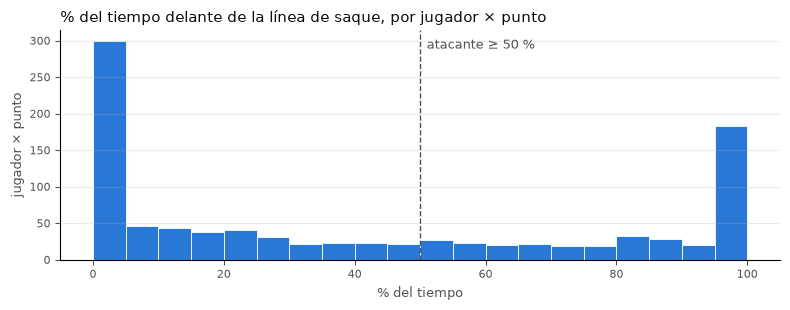

Guardado: data\interim\participaciones.csv
Guardado: data\interim\jugadores.csv


In [20]:
from src import variables as var

umbrales = var.umbrales_movimiento(video_limpio)
print('Umbrales globales de movimiento (m/s):', umbrales)
var_jugador = var.variables_jugador(video_limpio, umbrales)
estilo = var.estilo_jugador(var_jugador)

antes = datos.resumen_tabla(participaciones, 'participaciones (antes)')
participaciones = participaciones.merge(var_jugador.drop(columns='pose_coverage'), on=['partido', 'punto', 'codigo'], how='left')
jugadores = jugadores.drop(columns=[c for c in estilo.columns if c != 'codigo' and c in jugadores]).merge(estilo, on='codigo', how='left')
display(datos.comparar(antes, datos.resumen_tabla(participaciones, 'participaciones (con variables 1.9)')))
print('Variables jugador × punto (1.029 tracks con video):')
display(var_jugador.drop(columns=['partido', 'punto', 'codigo']).describe().T.round(2))
print(f"Jugador × punto atacantes: {100 * var_jugador['atacante'].mean():.1f} % | "
      f"jugadores atacantes: {int(estilo['estilo_atacante'].sum())} de {len(estilo)}")
display(estilo.merge(jugadores[['codigo', 'nombre']], on='codigo').sort_values('pct_puntos_atacante', ascending=False)
        [['nombre', 'puntos_con_estilo', 'pct_puntos_atacante', 'estilo_atacante']])

fig, eje = plt.subplots(figsize=(8, 3.2))
eje.hist(var_jugador['pct_zona_atacante'].dropna(), bins=20, color=COLOR, edgecolor='white', linewidth=0.6)
eje.axvline(50, color=TINTA_2, linewidth=1, linestyle='--')
eje.text(51, eje.get_ylim()[1] * 0.92, 'atacante ≥ 50 %', fontsize=9, color=TINTA_2)
eje.set_title('% del tiempo delante de la línea de saque, por jugador × punto', fontsize=11, color=TINTA, loc='left')
eje.set_xlabel('% del tiempo', fontsize=9, color=TINTA_2)
eje.set_ylabel('jugador × punto', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=8)
eje.grid(axis='y', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

print('Guardado:', datos.guardar_tabla(participaciones, 'participaciones').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(jugadores, 'jugadores').relative_to(RAIZ))

**Resultado**
- **Umbrales:** quieto por debajo de 0,37 m/s; ráfaga por encima de 1,28 m/s.
- **Cobertura:** 1.029 jugador × punto con video. Tienen variables de profundidad 979 (faltan los tracks de menos de 2 s y los del partido 17, sin `y`) y variables de pose 914 (cobertura de al menos el 50 %).
- **Estilo:** el 40 % de los jugador × punto es atacante, y 11 de los 30 jugadores lo son en al menos la mitad de sus puntos. El histograma muestra dos grupos: quienes casi siempre juegan detrás de la línea de saque y quienes casi siempre juegan delante.
- **Valores típicos (medianas):** área cubierta de 2,5 m², 48 % del tiempo quieto, 0,9 golpes por segundo y 100 % del tiempo en su propio lado.
- Salidas: `participaciones.csv` (con las variables 1.9) y `jugadores.csv` (con el estilo del jugador).

## 1.10 Variables pareja × punto y filtros

**Objetivo:** una fila por punto con las variables de cada pareja y su diferencia con el rival. Se aplican filtros que no miran el resultado y se entrega la tabla para el modelo.

**Decisiones**
- **D20:** solo los 244 puntos con los 4 jugadores identificados.
- **D32 (construcción):**
  - **Del jugador a la pareja:** para cada variable, la suma de los dos compañeros (capacidad) y su diferencia absoluta (complementariedad). Para velocidad p90, golpes por segundo y área se agrega además la razón mínimo/máximo (balance).
  - **Estilo de la pareja:** la suma de `atacante` es el número de atacantes (0, 1 o 2).
  - **Cohesión:** media y desviación de la distancia entre compañeros.
  - **Sincronía:** correlación, frame a frame, de la velocidad y de la profundidad de los dos compañeros.
  - **Variables fijas** (de `jugadores`): estatura, IMC, edad, género, mano, nivel, tiempo jugando, experiencia, otra raqueta, estado físico, frecuencia de deporte y lesiones. Además, `en_lado_mano`: diestro que juega a la derecha o zurdo que juega a la izquierda.
  - **Orientación:** una fila por punto, con las variables de la pareja 1 (`e1_`), de la pareja 2 (`e2_`) y su diferencia equipo 1 − equipo 2 (`dif_`). La duración del punto entra como contexto. El lado no se incluye porque es constante: el equipo 1 siempre está en BOTTOM.
- **D33 (faltantes y filtros):**
  - **Faltantes:** quedan NaN en esta tabla; se imputan en la fase 2 solo con datos de entrenamiento.
  - **Filtros, en orden y sin usar el resultado:**
    1. faltantes en más del 20 % de los puntos;
    2. varianza baja: un mismo valor en al menos el 95 % de los puntos;
    3. correlación de Pearson |r| ≥ 0,85.
  - **Qué se entrega:** todas las variables que pasan los filtros. La selección final de 10 a 15 se hace en la fase 2 con Lasso y Ridge dentro de la validación (D27).

**¿Qué es la correlación de Pearson?** Mide de −1 a 1 qué tan bien dos variables siguen una línea recta. Si |r| ≥ 0,85, dos variables cuentan casi lo mismo y basta con una. Se conserva la de menos faltantes; si empatan, la relativa al rival (`dif_`).

In [21]:
parejas = var.tabla_parejas(participaciones, var_jugador, jugadores, puntos, video_limpio)
conservadas, filtros = var.filtrar_variables(parejas)
tabla_modelo = parejas[['partido', 'punto', 'punto_equipo_1', *conservadas]]

display(datos.comparar(datos.resumen_tabla(parejas, 'parejas_punto (todas las variables)'),
                       datos.resumen_tabla(tabla_modelo, 'tabla_modelo (tras los filtros)')))
candidatas = parejas.shape[1] - 3
print(f'Variables candidatas: {candidatas} | descartadas: {len(filtros)} | conservadas: {len(conservadas)}')
display(filtros['filtro'].value_counts().rename('variables descartadas').to_frame())
prefijo = lambda c: c.split('_')[0] if c.split('_')[0] in {'e1', 'e2', 'dif'} else 'contexto'
print('Descartadas por faltantes, según pareja:', filtros.loc[filtros['filtro'] == 'faltantes', 'variable'].map(prefijo).value_counts().to_dict())
print('Conservadas por tipo:', pd.Series(conservadas).map(prefijo).value_counts().to_dict())
print(f"Balance del objetivo en los 244 puntos: el equipo 1 gana el {100 * tabla_modelo['punto_equipo_1'].mean():.1f} %")
display(filtros.head(15))

print('Guardado:', datos.guardar_tabla(parejas, 'parejas_punto').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(filtros, 'filtros_variables').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(tabla_modelo, 'tabla_modelo', carpeta=datos.DATA_PROCESSED).relative_to(RAIZ))

D:\Miguel Delgado\universidad\2026-2\Analitica de Datos\analitica v2\Proyecto Final\Proyecto_final_analitica\src\variables.py:166: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla = pd.concat([e1.add_prefix('e1_'), e2.add_prefix('e2_'), (e1 - e2).add_prefix('dif_')], axis=1).reset_index()
D:\Miguel Delgado\universidad\2026-2\Analitica de Datos\analitica v2\Proyecto Final\Proyecto_final_analitica\src\variables.py:166: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla = pd.concat([e1.add_prefix('e1_'), e2.add_prefix('e2_'), (

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,parejas_punto (todas las variables),244,247,4618,7.66
1,tabla_modelo (tras los filtros),244,164,1394,3.48


Variables candidatas: 244 | descartadas: 83 | conservadas: 161


,variables descartadas
filtro,
faltantes,42
correlación,41


Descartadas por faltantes, según pareja: {'e2': 21, 'dif': 21}
Conservadas por tipo: {'e1': 67, 'dif': 50, 'e2': 43, 'contexto': 1}
Balance del objetivo en los 244 puntos: el equipo 1 gana el 43.4 %


,variable,filtro,detalle
0,e2_suma_pct_juego_aereo,faltantes,27 % NaN
1,e2_suma_pct_raqueta_arriba,faltantes,27 % NaN
2,e2_suma_pct_raqueta_abajo,faltantes,27 % NaN
3,e2_suma_pct_raqueta_lateral,faltantes,27 % NaN
4,e2_suma_sd_angulo_codo,faltantes,27 % NaN
5,e2_suma_sd_angulo_hombro,faltantes,27 % NaN
6,e2_suma_sd_orientacion_raqueta,faltantes,27 % NaN
7,e2_suma_indice_golpe_p90,faltantes,27 % NaN
8,e2_suma_indice_golpe_p95,faltantes,27 % NaN
9,e2_suma_golpes_por_s,faltantes,27 % NaN


Guardado: data\interim\parejas_punto.csv
Guardado: data\interim\filtros_variables.csv
Guardado: data\processed\tabla_modelo.csv


**Resultado**
- **Tabla de parejas:** 244 puntos y 244 variables candidatas (más la llave y el objetivo).
- **Filtros:** salen 42 variables por faltantes y 41 por correlación; ninguna por varianza baja. Las 42 de faltantes son todas de pose: 21 de la pareja 2 y sus 21 diferencias con el rival, cada una con 27 % de NaN. Ese es el porcentaje de puntos en que algún jugador de la pareja 2 tiene menos del 50 % de cobertura de pose (D31).
- **Objetivo:** en estos 244 puntos, el equipo 1 gana el 43,4 %.
- **Tabla para el modelo:** quedan 161 variables en `data/processed/tabla_modelo.csv`. Es más que la meta de 10 a 15; la reducción final la hacen Lasso y Ridge en la fase 2, dentro de la validación, para no inflar las métricas.
- **Otras salidas:** `parejas_punto.csv` (todas las variables) y `filtros_variables.csv` (qué variable salió y por qué), ambas en `data/interim/`.

## 1.11 Variables para las fases 2 a 4

**Objetivo:** fijar la lista de variables que usan el modelo (fase 2), las distribuciones (fase 3) y la simulación (fase 4), y comprobar que cada una se puede armar desde los jugadores por separado.

**¿Por qué hace falta?** La fase 4 inventa partidos entre parejas que nunca jugaron juntas. Para eso, cada variable de pareja tiene que salir de los valores de sus dos jugadores, y no de algo que solo se mide cuando juegan juntos. Si el modelo usara una variable que no se puede armar así, la simulación no podría usarlo.

**Decisiones (D34)**
- **Criterios:**
  1. **Se reconstruye desde cada jugador:** la variable de pareja es la suma, la diferencia absoluta o la razón mín/máx de los dos compañeros (D32). Con los dos jugadores de cada lado se arma la pareja, y la `dif_` es pareja 1 − pareja 2.
  2. **Existe para las dos parejas:** cualquier pareja puede quedar como equipo 1 o como equipo 2 en la simulación.
  3. **Solo `dif_`:** las versiones `e1_` y `e2_` repiten la información, y como el equipo 1 siempre está en BOTTOM, las `e1_` mezclan el estilo con el lado de la cámara.
  4. **Estilo o control de nivel:** el nivel entra como control, para que el efecto del estilo no sea en realidad «ganan los que juegan mejor».
- **Las 19 variables** (`var.VARIABLES_MODELO`):

| Grupo | Variables | Qué mide |
|---|---|---|
| Estilo y posición (5) | `suma_atacante`, `absdif_atacante`, `absdif_prof_media_m`, `suma_prof_sd_m`, `suma_pct_en_su_lado` | Número de atacantes, si mezclan un atacante con un defensor, si juegan escalonados o en paralelo, cuánto suben y bajan, y cuánto respeta cada uno su lado |
| Movimiento (6) | `suma_vel_p90`, `razon_vel_p90`, `suma_area_m2`, `razon_area_m2`, `suma_pct_quieto`, `suma_rafagas_por_min` | Velocidad, balance de velocidad entre los dos, cancha cubierta, reparto de esa cobertura, tiempo quietos y explosividad |
| Nivel y atributos fijos (8) | `suma_nivel_padel`, `absdif_nivel_padel`, `suma_tiempo_jugando_padel`, `suma_practica_otra_raqueta`, `suma_frecuencia_deporte`, `suma_estatura_cm`, `suma_imc`, `absdif_mujer` | Nivel, desbalance de nivel, experiencia, otros deportes de raqueta, condición física, alcance, complexión y si la pareja es mixta |

- **Se quita `dif_suma_mujer`** (aprobado por el equipo). Su correlación con `dif_suma_estatura_cm` es r = −0,85 (|r| en el umbral de D33): la pareja con más mujeres es la de menor estatura sumada, así que las dos dicen casi lo mismo. Por eso el filtro de la 1.10 ya la había sacado. Con ella, el VIF de la estatura es 12,8 y el suyo 10,3; por encima de 10 se considera que una variable se repite con las demás. Sin ella, el VIF de la estatura baja a 2,7. Se conserva la estatura porque además mide alcance. `dif_absdif_mujer` sí queda: distingue las parejas mixtas y no repite la estatura.
- **Lo que queda fuera y por qué:**
  - **Pose, raqueta y golpes:** no tienen versión `dif_` (la pareja 2 tiene el 27 % de faltantes y salieron en la 1.10) y en BOTTOM dependen de la distancia a la cámara.
  - **Cohesión y sincronía:** solo existen cuando los dos juegan juntos; no se pueden armar desde cada jugador.
  - **`duracion_punto_s`:** solo se conoce al terminar el punto y no la controla la pareja. **`pose_coverage`:** mide la calidad del video, no el juego.
  - **Poca variación:** `en_lado_mano` (2 zurdos), `edad`, `pct_red` (1,7 % del tiempo cerca de la red).
  - **Repetidas con otra de la lista:** `distancia_m` (con el área), `suma_prof_media_m` (con atacante), `experiencia_padel` (con nivel y tiempo jugando), `pct_fondo` y `estado_fisico`.

**Para las fases siguientes:** la fase 2 parte de estas 19 variables y usa directamente `tabla_modelo`, que ya está en memoria (no se vuelve a leer del disco). Lo que deben tener en cuenta las fases 3 y 4 quedó como nota al inicio de cada una.

In [22]:
# 1) Cada dif_ se vuelve a armar desde los jugadores sueltos y se compara con la tabla de la 1.10
fijas = [c for c in var.VARIABLES_FIJAS if c in jugadores]
jp = (participaciones.drop(columns=fijas, errors='ignore').merge(jugadores[['codigo', *fijas]], on='codigo')
      .merge(tabla_modelo[['partido', 'punto']], on=['partido', 'punto']))
filas = []
for (p, q), g in jp.groupby(['partido', 'punto']):
    e1, e2 = g[g['equipo'] == 1], g[g['equipo'] == 2]
    pareja1 = var.combinar_pareja(e1.iloc[0], e1.iloc[1])
    pareja2 = var.combinar_pareja(e2.iloc[0], e2.iloc[1])
    filas.append({'partido': p, 'punto': q, **{v: pareja1[v] - pareja2[v] for v in var.VARIABLES_MODELO}})
reconstruida = pd.DataFrame(filas).set_index(['partido', 'punto'])
original = tabla_modelo.set_index(['partido', 'punto'])[var.VARIABLES_MODELO]
error = (reconstruida - original).abs().max()
mismos_nan = (reconstruida.isna() == original.isna()).all().all()
print(f'Puntos reconstruidos: {len(reconstruida)} | error máximo: {error.max():.1e} | mismos faltantes: {mismos_nan}')

# 2) Por qué sale dif_suma_mujer: correlación con la estatura y VIF con y sin ella
r = parejas['dif_suma_mujer'].corr(parejas['dif_suma_estatura_cm'])
print(f'Correlación dif_suma_mujer con dif_suma_estatura_cm: r = {r:.2f}')
con_mujer = var.vif(parejas, [*var.VARIABLES_MODELO, 'dif_suma_mujer'])
sin_mujer = var.vif(tabla_modelo, var.VARIABLES_MODELO)
display(pd.concat({'VIF con dif_suma_mujer': con_mujer, 'VIF sin ella (las 19)': sin_mujer}, axis=1).round(1).head(8))
display(datos.resumen_tabla(tabla_modelo[var.VARIABLES_MODELO], 'las 19 variables del modelo'))

Puntos reconstruidos: 244 | error máximo: 0.0e+00 | mismos faltantes: True
Correlación dif_suma_mujer con dif_suma_estatura_cm: r = -0.85


,VIF con dif_suma_mujer,VIF sin ella (las 19)
dif_suma_estatura_cm,12.8,2.7
dif_suma_mujer,10.3,NaN
dif_suma_area_m2,4.2,4.1
dif_suma_nivel_padel,3.7,3.0
dif_suma_vel_p90,3.4,3.3
dif_suma_prof_sd_m,2.8,2.8
dif_suma_rafagas_por_min,2.6,2.5
dif_suma_imc,2.4,2.3


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,las 19 variables del modelo,244,19,211,4.55


**Resultado**
- **Se reconstruyen desde cada jugador:** al volver a armar las 19 variables desde los jugadores sueltos (`var.combinar_pareja`) en los 244 puntos, el error máximo frente a `tabla_modelo` es 0 y los faltantes coinciden. Cada `dif_` es una cuenta exacta sobre los cuatro jugadores, así que la fase 4 puede armar cualquier pareja.
- **`dif_suma_mujer`:** r = −0,85 con la estatura sumada; con ella en la lista hay dos VIF por encima de 10 (12,8 y 10,3). Sin ella, el VIF más alto de las 19 es 4,1 (`dif_suma_area_m2`).
- **Faltantes:** 4,6 % de las celdas de las 19 variables; se imputan en la fase 2 con la mediana de entrenamiento (D33).
- **Para la fase 2:** la matriz de entrada es `tabla_modelo[var.VARIABLES_MODELO]` y el objetivo `tabla_modelo['punto_equipo_1']`.

---
# Fase 2 — Modelo predictivo

**Objetivo:** aprender a predecir quién gana cada punto (`punto_equipo_1`, D3) a partir de las 19 variables de estilo y nivel (D34). Ese modelo es el que la fase 4 usa para enfrentar parejas que nunca jugaron juntas.

**Dónde estamos en CRISP-DM**

| Etapa de CRISP-DM | Dónde está en el proyecto |
|---|---|
| Entendimiento del negocio | Objetivo del notebook: las parejas con más probabilidad de ganar |
| Entendimiento de los datos | 1.2 |
| Preparación de los datos | 1.3 a 1.11 y 2.1 |
| **Modelado** | **2.2 a 2.7** |
| **Evaluación** | **2.8** |
| Despliegue | Fases 3 y 4: el modelo elegido se usa para simular el torneo |

**Plan de la fase 2**

| Sección | Tema del curso | Qué se hace | Responsable |
|---|---|---|---|
| 2.1 | Pre-procesamiento y validación cruzada | `X`, `y`, partición train/test por partido y pliegues de validación | Miguel |
| 2.2 | Métricas de evaluación | Una evaluación común para todos los modelos | Miguel |
| 2.3 | Modelo naive y regresión logística | La referencia mínima y el modelo base (`statsmodels` y `scikit-learn`) | Miguel |
| 2.4 | LASSO, Ridge y árboles | Selección de 10 a 15 variables y un árbol de decisión | Miguel |
| 2.5 | Random Forest, SVM y hyperparameter tuning | Modelos avanzados con búsqueda de hiperparámetros | Compañero |
| 2.6 | Bagging y boosting | Árboles en bagging, AdaBoost y Gradient Boosting (red neuronal opcional) | Compañero |
| 2.7 | Ensamblaje de modelos | Voto de los mejores modelos | Compañero |
| 2.8 | Comparación final y bootstrap | Tabla de métricas en test, intervalos por bootstrap y modelo para la fase 4 | Compañero |

**Reglas que valen para toda la fase**
- **Nunca se mezclan puntos de un mismo partido** entre entrenamiento y prueba (D35).
- **Faltantes (D33):** se imputan con la mediana calculada solo con los datos de entrenamiento.
- **Métricas:** AUC, log-loss, Brier y calibración. La fase 4 necesita probabilidades bien calibradas, no solo acertar el ganador.
- **Formato:** cada sección sigue el estilo de los notebooks del profesor (`notebooks/referencias/`, prioridad a los numerados 01–07): primero la idea del método, luego el código y al final la lectura del resultado.

## 2.1 Pre-procesamiento y validación cruzada

**Objetivo:** dejar listos `X`, `y` y la forma de partir los datos, para que todos los modelos de la fase 2 se entrenen y se prueben con los mismos puntos.

**Decisiones**
- **D34:** `X` son las 19 variables de `var.VARIABLES_MODELO`; `y` es `punto_equipo_1`. Se toman de `tabla_modelo`, que ya está en memoria desde la 1.10.
- **D35 (partición, como en el profesor pero por partido):**
  - **Train y test:** el profesor separa el 20 % para test con `train_test_split(test_size=0.2, random_state=0)`. Aquí se hace lo mismo, pero el 20 % son **partidos completos**: 5 de los 25, con `GroupShuffleSplit` y la misma semilla. El test no se toca hasta la 2.8.
  - **Validación cruzada dentro del train:** el profesor usa k-fold. Aquí cada pliegue es un partido (`LeaveOneGroupOut`): se entrena con 19 partidos y se valida con el que quedó fuera, 20 veces.
  - **Por qué por partido:** los puntos de un mismo partido los juegan las mismas cuatro personas. Si un partido queda repartido entre train y test, el modelo reconoce a esas parejas y las métricas salen infladas.
- **D33:** los faltantes no se imputan aquí, sino dentro de cada pliegue con la mediana de entrenamiento (2.2).

### ¿Qué es la validación cruzada?
Es una forma de estimar qué tan bien le irá al modelo con datos nuevos usando todos los datos de entrenamiento, y no una sola partición que pudo salir con suerte. Los datos se dividen en partes (*folds*); en cada vuelta se entrena con todas menos una y se mide con la que quedó fuera, y al final se promedian las métricas. Aquí cada parte es un partido.

In [23]:
# Librerías de la fase 2 (se irán sumando en cada sección)
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut

In [24]:
# Variable objetivo: ¿cuántos puntos gana cada equipo? (1 = gana el equipo 1)
tabla_modelo['punto_equipo_1'].value_counts(), tabla_modelo['punto_equipo_1'].value_counts(normalize=True)

(punto_equipo_1
 0.0    138
 1.0    106
 Name: count, dtype: int64,
 punto_equipo_1
 0.0    0.565574
 1.0    0.434426
 Name: proportion, dtype: float64)

In [25]:
# X: las 19 variables de estilo y nivel (D34) | y: quién ganó el punto | grupos: el partido de cada punto
X = tabla_modelo[var.VARIABLES_MODELO]
y = tabla_modelo['punto_equipo_1'].astype(int)
grupos = tabla_modelo['partido']
print(f'X: {X.shape[0]} puntos x {X.shape[1]} variables | partidos: {grupos.nunique()}')

X: 244 puntos x 19 variables | partidos: 25


In [26]:
# Train y test como en el profesor (20 %, random_state=0), pero con partidos completos (D35)
particion = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
idx_train, idx_test = next(particion.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

print('Observaciones en entrenamiento: {} ({} partidos)'.format(len(X_train), grupos_train.nunique()))
print('Observaciones en Test: {} ({} partidos: {})'.format(len(X_test), grupos.iloc[idx_test].nunique(), sorted(grupos.iloc[idx_test].unique())))
print('¿Algún partido en los dos lados?:', bool(set(grupos_train) & set(grupos.iloc[idx_test])))

Observaciones en entrenamiento: 192 (20 partidos)
Observaciones en Test: 52 (5 partidos: [np.int64(5), np.int64(10), np.int64(18), np.int64(26), np.int64(29)])
¿Algún partido en los dos lados?: False


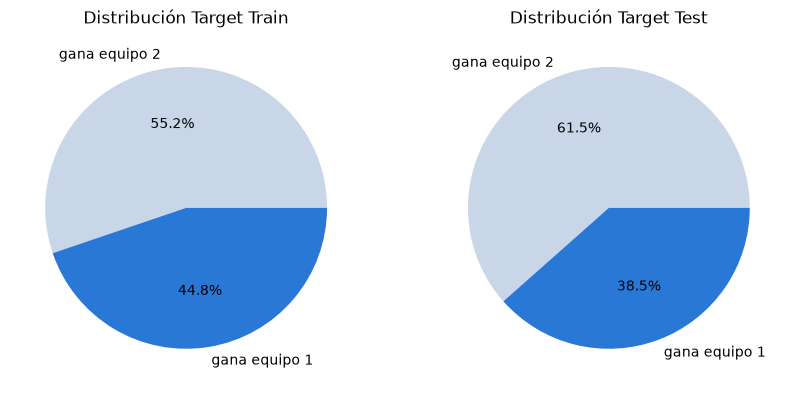

In [27]:
# Distribución del objetivo en train y en test (como en el profesor)
keys_train, counts_train = np.unique(y_train, return_counts=True)
keys_test, counts_test = np.unique(y_test, return_counts=True)
etiquetas = {0: 'gana equipo 2', 1: 'gana equipo 1'}

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.pie(counts_train / counts_train.sum(), labels=[etiquetas[k] for k in keys_train], autopct='%1.1f%%', colors=['#c9d6e8', '#2a78d6'])
plt.title('Distribución Target Train')
plt.subplot(1, 2, 2)
plt.pie(counts_test / counts_test.sum(), labels=[etiquetas[k] for k in keys_test], autopct='%1.1f%%', colors=['#c9d6e8', '#2a78d6'])
plt.title('Distribución Target Test')
plt.show()

In [28]:
# Validación cruzada dentro del train: un pliegue por partido (D35)
validacion = LeaveOneGroupOut()
pliegues = list(validacion.split(X_train, y_train, groups=grupos_train))

tamanos = pd.Series([len(val) for _, val in pliegues])
print(f'Pliegues: {len(pliegues)} | puntos de validación por pliegue: mín {tamanos.min()}, mediana {tamanos.median():.0f}, máx {tamanos.max()}')
print(f'Proporción de puntos que gana el equipo 1 por pliegue: entre {min(y_train.iloc[v].mean() for _, v in pliegues):.0%} y {max(y_train.iloc[v].mean() for _, v in pliegues):.0%}')

Pliegues: 20 | puntos de validación por pliegue: mín 6, mediana 10, máx 13
Proporción de puntos que gana el equipo 1 por pliegue: entre 0% y 78%


In [29]:
# Faltantes en train y test (se imputan dentro de cada pliegue en la 2.2, D33)
faltantes = pd.DataFrame({'% NaN train': X_train.isna().mean() * 100, '% NaN test': X_test.isna().mean() * 100}).round(1)
faltantes[faltantes.sum(axis=1) > 0].sort_values('% NaN train', ascending=False)

,% NaN train,% NaN test
dif_suma_atacante,8.3,7.7
dif_absdif_atacante,8.3,7.7
dif_absdif_prof_media_m,8.3,7.7
dif_suma_prof_sd_m,8.3,7.7
dif_suma_vel_p90,8.3,7.7
dif_razon_vel_p90,8.3,7.7
dif_suma_area_m2,8.3,7.7
dif_suma_pct_quieto,8.3,7.7
dif_razon_area_m2,8.3,7.7
dif_suma_rafagas_por_min,8.3,7.7


**Resultado**

Quedaron 192 puntos de 20 partidos para entrenar y 52 puntos de 5 partidos para el test, los partidos 5, 10, 18, 26 y 29, y ningun partido quedo repartido entre los dos lados que era lo que mas me importaba de toda esta parte. En train el equipo 1 gana el 44,8 % de los puntos y en test el 38,5 %, o sea el test salio un poco mas cargado hacia el equipo 2, no es grave pero toca tenrelo en cuenta en la 2.8 porque un modelo que diga siempre equipo 2 se va a ver mejor de lo que es en ese test.

La validacion cruzada quedo con 20 pliegues, uno por partdio, de entre 6 y 13 puntos cada uno. Muy pocos puntos. Eso hace que la metrica de cada pliegue salte muchismo, hay partidos como el 28 y el 35 donde el equipo 1 no gano ni un solo punto y en esos el auc ni siquiera se puede calcular porque solo hay una clase, entonces lo que toca es juntar las predicciones de todos los pliegues y medir al final con todo junto, eso lo resuelvo en la 2.2 cuando arme la evalaucion comun.

Los faltantes rondan el 8 % en las variables de movimiento, parecido en train y en test, y se imputan adentro de cada pliegue con la mediana de entrenamiento, nunca antes, porque si no el test ya estaria metido en la mediana. Seran suficientes 192 puntos para 19 variables ? por eso mismo esta lo de lasso en la 2.4, para quitarle variables al modelo antes de que se aprenda los partidos de memoria_

## 2.2 Métricas y evaluación común

**Objetivo:** definir una sola forma de entrenar y medir, para que todos los modelos de la 2.3 a la 2.7 se comparen en igualdad de condiciones.

**Decisiones**
- **D33:** cada modelo se envuelve con un imputador por mediana (`mod.con_imputacion`). Así la mediana se calcula solo con el train de cada pliegue y nunca con el partido que se valida.
- **D36 (AUC por pliegue):** el AUC se calcula dentro de cada partido validado y se promedia, como hace `cross_val_score(scoring='roc_auc')` en el notebook 05. Los partidos con una sola clase (el 28 y el 35, donde el equipo 1 no ganó ningún punto) no tienen AUC y se saltan. Log-loss, Brier, accuracy y F1 se calculan con todas las predicciones juntas. Abajo está la evidencia de por qué.

**Las funciones (`src/modelo.py`)**

| Función | Qué hace |
|---|---|
| `predecir_cv(modelo, X, y, pliegues)` | Entrena el modelo en cada pliegue y predice el partido que quedó fuera. Devuelve una probabilidad por punto, predicha por un modelo que no vio ese partido. |
| `metricas(y, p, pliegues)` | AUC por pliegue (media, desviación y cuántos pliegues), log-loss, Brier, accuracy y F1 con umbral 0,5. |
| `graficar_evaluacion(y, p, nombre, pliegues)` | AUC por partido (o curva ROC si es el test), curva de calibración y matriz de confusión. |

### Las métricas (como en el notebook 03)

**Matriz de confusión.** Cruza lo real con lo predicho. Aquí la clase positiva es *gana el equipo 1*:
- **TP:** puntos que ganó el equipo 1 y el modelo lo predijo.
- **TN:** puntos que ganó el equipo 2 y el modelo lo predijo.
- **FP:** el modelo dijo equipo 1 y ganó el equipo 2.
- **FN:** el modelo dijo equipo 2 y ganó el equipo 1.

| Métrica | Fórmula | Qué responde |
|---|---|---|
| Accuracy | $\dfrac{TP + TN}{TP + FP + FN + TN}$ | ¿Qué porcentaje de puntos acertó? |
| Precision | $\dfrac{TP}{TP + FP}$ | De los puntos que dijo que ganaba el equipo 1, ¿cuántos ganó? |
| Recall | $\dfrac{TP}{TP + FN}$ | De los puntos que ganó el equipo 1, ¿cuántos detectó? |
| F1 | $2 \times \dfrac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ | Equilibrio entre precision y recall |
| AUC-ROC | Área bajo la curva TPR vs FPR | ¿Le da más probabilidad a los puntos que gana el equipo 1 que a los que pierde? 0,5 es azar y 1 es perfecto |

### Dos métricas más: calidad de la probabilidad
El notebook 03 evalúa sobre todo si el modelo acierta la clase. Aquí además importa **qué tan buena es la probabilidad**, porque la fase 4 no usa la clase sino p(gana el punto) para simular partidos a 7 puntos. Un modelo que dice 0,9 cuando la realidad es 0,6 inventa parejas imbatibles.

| Métrica | Fórmula | Cómo se lee |
|---|---|---|
| Log-loss | $-\dfrac{1}{n}\sum \big[y_i \ln p_i + (1-y_i)\ln(1-p_i)\big]$ | Castiga mucho equivocarse con seguridad. Menor es mejor. |
| Brier | $\dfrac{1}{n}\sum (p_i - y_i)^2$ | Error cuadrático de la probabilidad. Menor es mejor; decir siempre 0,5 da 0,25. |
| Calibración | Gráfico: probabilidad predicha vs proporción real | Si el modelo dice 0,6, el equipo 1 debería ganar cerca del 60 % de esos puntos. Lo ideal es la diagonal. |

### Prueba de la evaluación con el modelo más simple
Para comprobar que las funciones miden bien, se prueban con `DummyClassifier(strategy='prior')`: un modelo que ignora las variables y siempre predice la proporción de puntos que ganó el equipo 1 en su train. Ese modelo no sabe nada, así que su AUC tiene que dar 0,5. En la 2.3 se usa como la referencia mínima que todo modelo debe superar.

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score
from src import modelo as mod

# Modelo que no sabe nada: siempre predice la proporción de puntos que ganó el equipo 1 en su train
naive = DummyClassifier(strategy='prior')
p_naive = mod.predecir_cv(naive, X_train, y_train, pliegues)
pd.Series(mod.metricas(y_train, p_naive, pliegues)).round(3)

AUC                  0.500
AUC_sd               0.000
pliegues_con_AUC    18.000
log_loss             0.696
Brier                0.251
accuracy             0.552
F1                   0.000
dtype: float64

In [31]:
# ¿Por qué el AUC por pliegue (D36)? Al juntar las predicciones de todos los pliegues, el naive sale peor que el azar
print(f'AUC juntando todas las predicciones: {roc_auc_score(y_train, p_naive):.3f}')
print(f'AUC media por pliegue:               {mod.auc_por_pliegue(y_train, p_naive, pliegues).mean():.3f}')

# La causa: cuando sale un partido que ganó mucho el equipo 1, la proporción del train baja, y viceversa
por_partido = pd.DataFrame({'gana_equipo_1_real': y_train.groupby(grupos_train).mean(),
                            'p_naive': p_naive.groupby(grupos_train).first()})
print(f"Correlación entre lo real de cada partido y lo que predice el naive: {por_partido.corr().iloc[0, 1]:.2f}")

AUC juntando todas las predicciones: 0.271
AUC media por pliegue:               0.500
Correlación entre lo real de cada partido y lo que predice el naive: -0.98


In [32]:
# Reporte de clasificación con umbral 0,5 (como en el profesor)
print(classification_report(y_train, (p_naive >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))

               precision    recall  f1-score   support

gana equipo 2       0.55      1.00      0.71       106
gana equipo 1       0.00      0.00      0.00        86

     accuracy                           0.55       192
    macro avg       0.28      0.50      0.36       192
 weighted avg       0.30      0.55      0.39       192



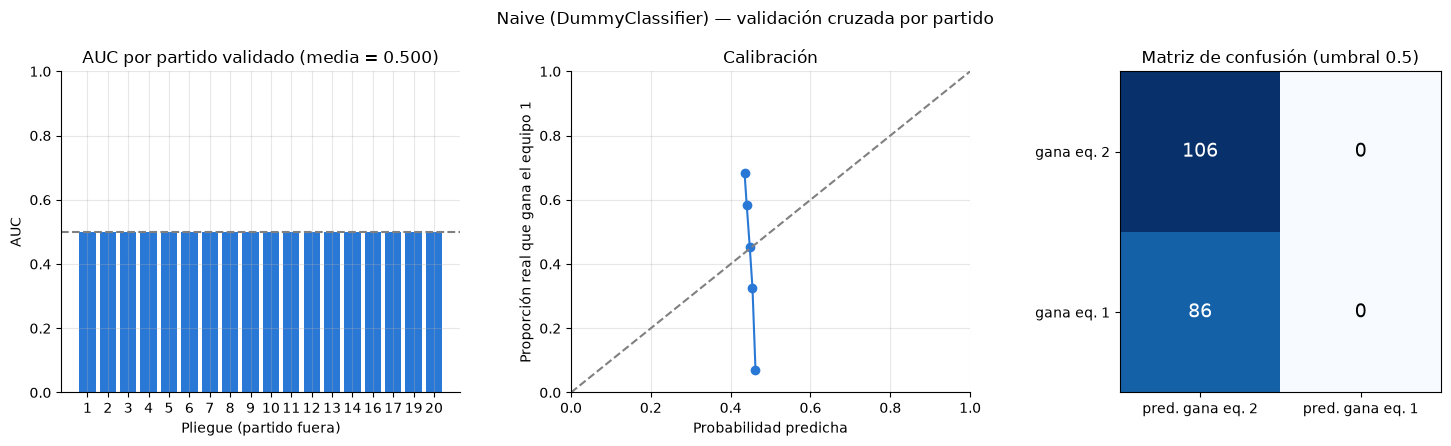

In [33]:
mod.graficar_evaluacion(y_train, p_naive, 'Naive (DummyClassifier) — validación cruzada por partido', pliegues)

In [34]:
# Tabla donde se acumulan los resultados de validación cruzada de cada modelo (se completa de la 2.3 a la 2.7)
resultados_cv = {'naive': mod.metricas(y_train, p_naive, pliegues)}
pd.DataFrame(resultados_cv).T.round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.5,0.0,18.0,0.696,0.251,0.552,0.0


**Resultado**

La evaluacion funciona y el naive da justo lo que tiene que dar, AUC de 0,5 en los 18 partidos que tienen las dos clases, log-loss de 0,696 y Brier de 0,251, que es casi lo mismo que decir siempre 0,5. Ese es el piso. Cualquier modelo de la 2.3 en adelante que no baje de 0,696 en log-loss y de 0,251 en Brier no aprendio nada de las variables, por mas bonito que se vea.

Lo que mas me sorprendio fue el AUC juntando todas las predicciones, 0,271, peor que tirar una moneda para un modelo que ni siquiera mira los datos. La razon esta en la correlacion de -0,98 entre lo que pasó en cada partido y lo que predice el naive, cuando sale un partido donde el equipo 1 gano mucho, el train que queda tiene menos victorias del equipo 1 y el modelo predice mas bajo justo ahi. Siempre al revés. Por eso el auc se mide adentro de cada partido y se promedia, como hace el profe con cross_val_score, y no con todo junto.

El mismo efecto se ve en la calibracion, los puntos quedan todos entre 0,43 y 0,46 y forman una linea que baja en vez de seguir la diagonal, entonces esa grafica sirve para comparar modelos que si muevan la probabilidad, no para el naive. Con umbral de 0,5 el naive dice equipo 2 en los 192 puntos, por eso el accuracy de 55 % y el F1 en cero. El accuracy solito engaña bastante aca, no ?

## 2.3 Regresión logística: el modelo base

**Objetivo:** estimar el modelo base de la fase 2 y entender qué variables de estilo y nivel mueven la probabilidad de ganar el punto.

**Decisiones**
- **D28:** la regresión logística es el modelo base contra el que se comparan los avanzados.
- **D37 (cómo se interpreta):**
  - Para leer los coeficientes, las 19 variables se **estandarizan** (media 0 y desviación 1, con la media y la desviación del train). Así el odds ratio de cada variable es el efecto de subirla **una desviación estándar**, y las variables se pueden comparar entre sí aunque estén en unidades distintas (metros, niveles, porcentajes).
  - Los p-valores usan errores estándar **agrupados por partido** (`cov_type='cluster'`), porque los puntos de un mismo partido los juegan las mismas cuatro personas y no son independientes. Con errores normales los p-valores saldrían más optimistas.
- **D33:** los faltantes se imputan con la mediana del train.
- **Referencia:** `03_Regresion_Logistica.ipynb`, en el mismo orden: primero por qué no sirve la regresión lineal, luego la mirada estadística con `statsmodels` y al final el modelo para predecir con `scikit-learn`.

### ¿Por qué no una regresión lineal?
La variable respuesta vale 1 si gana el equipo 1 y 0 si no. Como es un número, se podría intentar una regresión lineal múltiple:

$$y_i = \beta_0 + \beta_1 x_{1i} + \dots + \beta_{19} x_{19,i} + \varepsilon_i$$

El problema, como muestra el notebook 03:
1. La recta está definida en todos los reales, pero lo que queremos predecir es una probabilidad en [0, 1].
2. El ajuste ($R^2$) siempre es pobre, porque la respuesta solo toma dos valores.
3. Los supuestos (por ejemplo, errores normales) pierden sentido con una respuesta 0/1.

In [35]:
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Matriz de diseño para statsmodels: imputada con la mediana del train y estandarizada con el train (D33, D37)
mediana_train = X_train.median()
media_train, sd_train = X_train.fillna(mediana_train).mean(), X_train.fillna(mediana_train).std()
X_train_sm = sm.add_constant((X_train.fillna(mediana_train) - media_train) / sd_train, has_constant='add')

ols = sm.OLS(y_train, X_train_sm).fit()
pred_ols = ols.predict(X_train_sm)
print(f'R² de la regresión lineal: {ols.rsquared:.3f}')
print(f'Predicciones fuera de [0, 1]: {((pred_ols < 0) | (pred_ols > 1)).sum()} de {len(pred_ols)} | rango: {pred_ols.min():.2f} a {pred_ols.max():.2f}')

R² de la regresión lineal: 0.170
Predicciones fuera de [0, 1]: 1 de 192 | rango: -0.03 a 0.99


### El modelo de regresión logística
Se modela la probabilidad $\pi_i = P(Y_i = 1 \mid X_i)$ de que gane el equipo 1 con la transformación **logit**:

$$\ln\left(\frac{\pi_i}{1-\pi_i}\right) = \beta_0 + X_i^\top \beta \quad\Longleftrightarrow\quad \pi_i = \frac{1}{1 + e^{-(\beta_0 + X_i^\top \beta)}}, \qquad Y_i \sim \text{Bernoulli}(\pi_i)$$

- $\dfrac{\pi_i}{1-\pi_i}$ son los **odds**: cuántas veces es más probable que gane el equipo 1 que el equipo 2.
- **Odds ratio** $e^{\beta_j}$: cuánto se multiplican los odds cuando la variable $j$ sube una desviación estándar, con todo lo demás fijo. Mayor que 1 ayuda al equipo 1; menor que 1 lo perjudica; 1 no tiene efecto.
- Como todas las variables son `dif_` (equipo 1 − equipo 2), un odds ratio mayor que 1 quiere decir que **tener más de esa variable que el rival** ayuda a ganar el punto.

### Paso 1: la mirada estadística con `statsmodels`

In [36]:
# Estimación por máxima verosimilitud, con errores estándar agrupados por partido (D37)
logit_sm = sm.Logit(y_train, X_train_sm).fit(cov_type='cluster', cov_kwds={'groups': grupos_train}, disp=0)
print(logit_sm.summary())

                           Logit Regression Results                           
Dep. Variable:         punto_equipo_1   No. Observations:                  192
Model:                          Logit   Df Residuals:                      172
Method:                           MLE   Df Model:                           19
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.1349
Time:                        22:09:07   Log-Likelihood:                -114.23
converged:                       True   LL-Null:                       -132.04
Covariance Type:              cluster   LLR p-value:                   0.01175
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -0.2650      0.113     -2.345      0.019      -0.487      -0.044
dif_suma_atacante                  0.1549      0.185      0.839      0.

### ¿Cómo se lee esta salida? (igual que en el 03)
- **`converged: True`:** el algoritmo encontró el máximo de la verosimilitud.
- **`LLR p-value`:** prueba si *todos* los $\beta_j$ son 0 a la vez. Si es menor que 0,05, el modelo aporta algo frente a solo el intercepto.
- **`Pseudo R-squ.` (McFadden):** $1 - \ell_{\text{modelo}} / \ell_{\text{nulo}}$. No se lee como el $R^2$ de la regresión lineal.
- **`coef`:** $\hat\beta_j$ en la escala del logit. **`P>|z|`:** el p-valor de $H_0: \beta_j = 0$. **`[0.025 0.975]`:** el intervalo del 95 %; si contiene el 0, el coeficiente no es significativo.

In [37]:
# Los betas traducidos a odds ratio (como en el 03)
tabla_or = pd.DataFrame({
    'beta': logit_sm.params,
    'error_std': logit_sm.bse,
    'p_valor': logit_sm.pvalues,
    'odds_ratio': np.exp(logit_sm.params),
})
ic = np.exp(logit_sm.conf_int())
tabla_or['OR_ic_inf'], tabla_or['OR_ic_sup'] = ic[0], ic[1]
tabla_or['significativo_5%'] = np.where(tabla_or['p_valor'] < 0.05, 'Sí', 'No')
tabla_or['efecto'] = np.where(tabla_or['beta'] > 0, '↑ prob. de ganar el equipo 1', '↓ prob. de ganar el equipo 1')

intercepto = tabla_or.loc['const']
tabla_or = tabla_or.drop(index='const').sort_values('beta', ascending=False)
print(f"Intercepto = {intercepto['beta']:.3f} -> probabilidad de que gane el equipo 1 con todas las dif_ en su media: {1 / (1 + np.exp(-intercepto['beta'])):.3f}")
tabla_or.round(3)

Intercepto = -0.265 -> probabilidad de que gane el equipo 1 con todas las dif_ en su media: 0.434


,beta,error_std,p_valor,odds_ratio,OR_ic_inf,OR_ic_sup,significativo_5%,efecto
dif_suma_nivel_padel,0.539,0.222,0.015,1.714,1.109,2.649,Sí,↑ prob. de ganar el equipo 1
dif_suma_pct_quieto,0.439,0.188,0.019,1.551,1.073,2.242,Sí,↑ prob. de ganar el equipo 1
dif_suma_imc,0.276,0.197,0.162,1.317,0.895,1.939,No,↑ prob. de ganar el equipo 1
dif_absdif_nivel_padel,0.224,0.127,0.076,1.252,0.976,1.604,No,↑ prob. de ganar el equipo 1
dif_suma_rafagas_por_min,0.207,0.285,0.468,1.230,0.704,2.150,No,↑ prob. de ganar el equipo 1
dif_suma_practica_otra_raqueta,0.169,0.131,0.196,1.185,0.917,1.531,No,↑ prob. de ganar el equipo 1
dif_suma_atacante,0.155,0.185,0.401,1.168,0.813,1.676,No,↑ prob. de ganar el equipo 1
dif_razon_area_m2,0.087,0.172,0.612,1.091,0.779,1.528,No,↑ prob. de ganar el equipo 1
dif_razon_vel_p90,0.043,0.279,0.878,1.044,0.604,1.803,No,↑ prob. de ganar el equipo 1
dif_suma_area_m2,0.035,0.349,0.919,1.036,0.522,2.055,No,↑ prob. de ganar el equipo 1


In [38]:
# Efectos marginales: el mismo beta, pero en escala de probabilidad
# dy/dx = cuánto cambia, en promedio, la probabilidad de que gane el equipo 1 al subir la variable una desviación estándar
print(logit_sm.get_margeff(at='overall', method='dydx').summary())

        Logit Marginal Effects       
Dep. Variable:         punto_equipo_1
Method:                          dydx
At:                           overall
                                    dy/dx    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
dif_suma_atacante                  0.0317      0.037      0.847      0.397      -0.042       0.105
dif_absdif_atacante               -0.0041      0.042     -0.097      0.922      -0.087       0.079
dif_absdif_prof_media_m           -0.0330      0.040     -0.822      0.411      -0.112       0.046
dif_suma_prof_sd_m                -0.0340      0.070     -0.483      0.629      -0.172       0.104
dif_suma_pct_en_su_lado           -0.0319      0.033     -0.972      0.331      -0.096       0.032
dif_suma_vel_p90                  -0.0650      0.057     -1.144      0.253      -0.176       0.046
dif_razon_vel_p90                  0.0088      0.057    

### Paso 2: el modelo para predecir con `scikit-learn`
Como en el 03, `LogisticRegression` trae **regularización L2 por defecto** (`C=1.0`), así que sus coeficientes salen encogidos hacia 0 y no son comparables con los de `statsmodels`. Aquí se usa para predecir: se estandariza dentro de un pipeline y se evalúa con la validación cruzada por partido de la 2.2.

In [39]:
logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
p_logistica = mod.predecir_cv(logistica, X_train, y_train, pliegues)

resultados_cv['logistica'] = mod.metricas(y_train, p_logistica, pliegues)
pd.DataFrame(resultados_cv).T.round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527


               precision    recall  f1-score   support

gana equipo 2       0.62      0.65      0.64       106
gana equipo 1       0.54      0.51      0.53        86

     accuracy                           0.59       192
    macro avg       0.58      0.58      0.58       192
 weighted avg       0.59      0.59      0.59       192



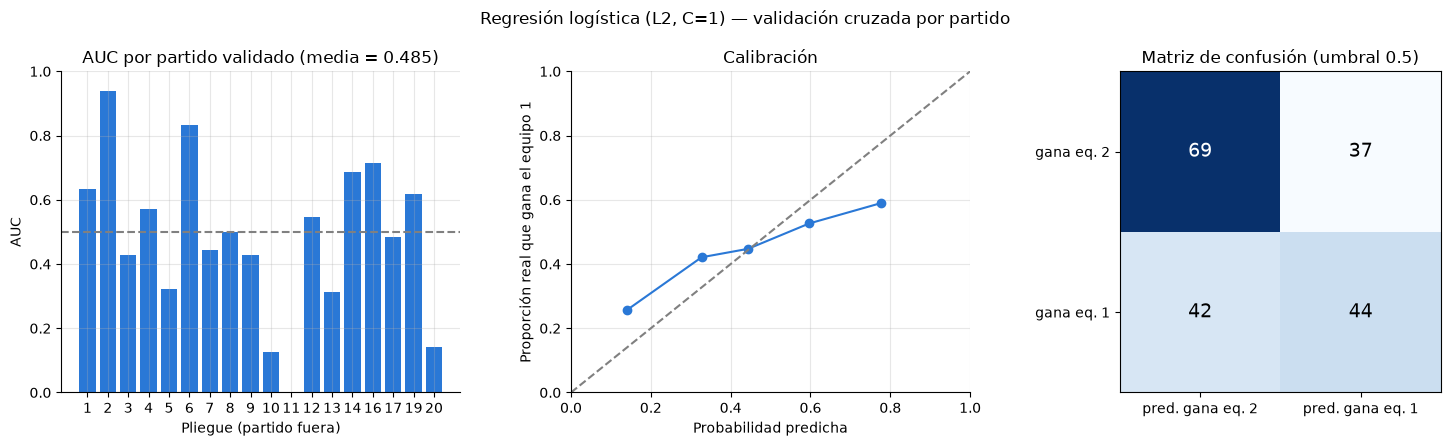

In [40]:
print(classification_report(y_train, (p_logistica >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_logistica, 'Regresión logística (L2, C=1) — validación cruzada por partido', pliegues)

**Resultado**

La regresion lineal saca un R² de 0,17 y una sola prediccion de 192 se sale de [0, 1], va de -0,03 a 0,99, o sea aca el problema de la recta casi no se nota porque las probabilidades de este juego estan todas en la mitad, nadie gana el 95 % de los puntos. Igual la logistica es la que tiene sentido para una respuesta de 0 y 1, asi que seguimos con esa.

En statsmodels el modelo completo si aporta frente a solo el intercepto, el LLR p-value da 0,012 y el pseudo R² de McFadden 0,135. De las 19 variables solo dos salen significativas al 5 % con los errores agrupados por partido. dif_suma_nivel_padel con odds ratio de 1,71, cada desviacion estandar mas de nivel sumado que el rival multiplica por 1,71 los odds de ganar el punto. Y dif_suma_pct_quieto con 1,55, la pareja que pasa mas tiempo quieta que el rival gana mas puntos. Esa segunda no me la esperaba. Puede ser que quedarse quieto sea estar bien parado y no tener que correr detras de la pelota, pero eso es una hipotesis mia, el modelo solo dice que van juntas, no que una cause la otra.

Lo que si preocupa es la logistica de scikit-learn con C=1, en validacion por partido saca log-loss de 0,715 y AUC de 0,485, peor que el naive en las dos. Con 192 puntos y 19 variables el modelo se aprende los partidos de entrenamiento y falla en el que no vio, el p-valor bonito de statsmodels es dentro de muestra y la validacion es fuera. por eso hace falta la 2.4

## 2.4 LASSO, Ridge y árbol de decisión

**Objetivo:** reducir las 19 variables a las que de verdad aportan (D27) y probar un primer modelo no lineal que se pueda leer.

**Decisiones**
- **D27:** LASSO (L1) y Ridge (L2) se aplican dentro de la validación cruzada por partido, para no inflar las métricas. La meta era quedar con 10 a 15 variables.
- **D38 (cómo se elige la perilla):** la fuerza de la penalización (`C`) y la profundidad del árbol (`max_depth`) se eligen con el **log-loss** de la validación cruzada (2.2), porque es la métrica de la probabilidad, que es lo que usa la fase 4. El AUC por pliegue se muestra al lado.
- **Referencia:** `Regresion_Ridge_Lasso.ipynb` y `Arboles_regresion. 1.ipynb` (de estudiantes; se adaptan a clasificación).

### Ridge y LASSO: ponerle disciplina al modelo
Con 192 puntos y 19 variables, la regresión logística puede **sobreajustarse**: aprende el ruido de los partidos de entrenamiento y falla en los nuevos. Ridge y LASSO agregan un castigo al tamaño de los coeficientes:

$$\text{Ridge (L2)}: \quad -\ell(\beta) + \lambda \sum_j \beta_j^2 \qquad\qquad \text{LASSO (L1)}: \quad -\ell(\beta) + \lambda \sum_j |\beta_j|$$

- **Ridge** encoge todos los coeficientes hacia 0, pero ninguno llega a 0: conserva todas las variables.
- **LASSO** puede dejar coeficientes **exactamente en 0**: elimina variables. Por eso sirve para seleccionar.
- **En `scikit-learn` (versión 1.8):** el tipo de castigo se elige con `l1_ratio` (1 = LASSO, 0 = Ridge). La perilla es $C = 1/\lambda$: **C pequeño = más castigo** = coeficientes más chicos (y en LASSO, menos variables). Las variables tienen que estar estandarizadas para que el castigo sea parejo.

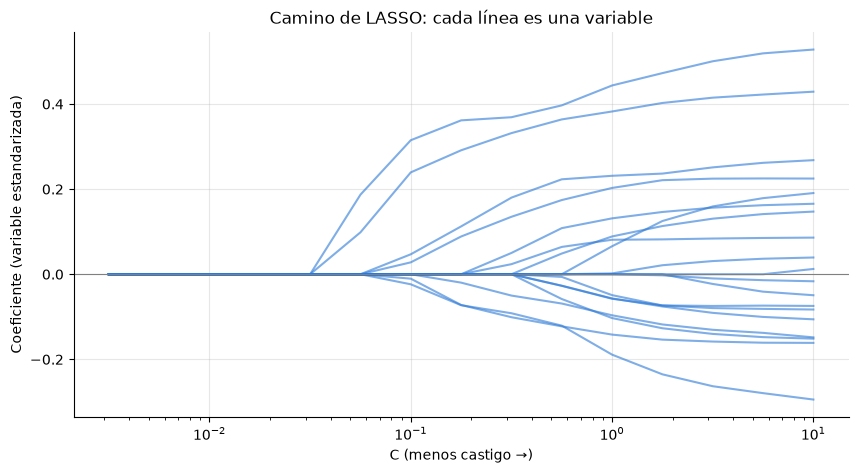

In [41]:
# Camino de LASSO: cómo cambian los coeficientes al aflojar el castigo (C de menor a mayor)
valores_C = np.logspace(-2.5, 1, 15)
X_train_std = (X_train.fillna(mediana_train) - media_train) / sd_train
camino = pd.DataFrame({C: LogisticRegression(l1_ratio=1, solver='liblinear', C=C).fit(X_train_std, y_train).coef_[0]
                       for C in valores_C}, index=var.VARIABLES_MODELO).T

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(camino.index, camino.values, color='#2a78d6', alpha=0.6)
ax.set(xscale='log', xlabel='C (menos castigo →)', ylabel='Coeficiente (variable estandarizada)', title='Camino de LASSO: cada línea es una variable')
ax.axhline(0, color='gray', linewidth=0.8)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

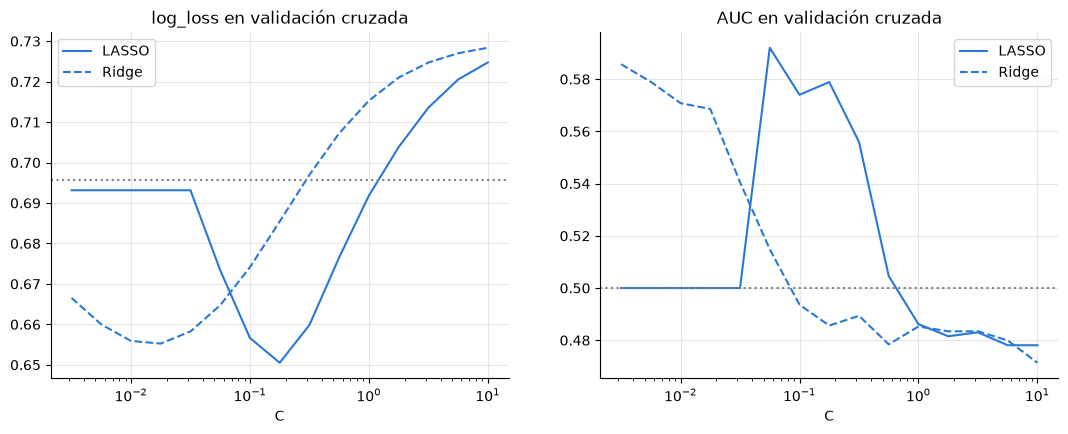

,C,log_loss,AUC
modelo,,,
LASSO,0.1778,0.6505,0.5789
Ridge,0.0178,0.6552,0.5686


In [42]:
# Selección de C con la validación cruzada por partido (D38), para LASSO y para Ridge
filas = []
for C in valores_C:
    for nombre, l1 in [('LASSO', 1), ('Ridge', 0)]:
        m = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=l1, solver='liblinear', C=C))
        met = mod.metricas(y_train, mod.predecir_cv(m, X_train, y_train, pliegues), pliegues)
        filas.append({'modelo': nombre, 'C': C, 'log_loss': met['log_loss'], 'AUC': met['AUC']})
curva_C = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, metrica in zip(ax, ['log_loss', 'AUC']):
    for nombre, estilo in [('LASSO', '-'), ('Ridge', '--')]:
        d = curva_C[curva_C['modelo'] == nombre]
        a.plot(d['C'], d[metrica], estilo, color='#2a78d6', label=nombre)
    a.set(xscale='log', xlabel='C', title=f'{metrica} en validación cruzada')
    a.grid(alpha=0.3)
    a.spines[['top', 'right']].set_visible(False)
    a.legend()
ax[0].axhline(resultados_cv['naive']['log_loss'], color='gray', linestyle=':')
ax[1].axhline(0.5, color='gray', linestyle=':')
plt.show()

mejor_C = curva_C.loc[curva_C.groupby('modelo')['log_loss'].idxmin()].set_index('modelo')
mejor_C.round(4)

In [43]:
# Modelos con el mejor C, evaluados igual que los demás
lasso = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver='liblinear', C=mejor_C.loc['LASSO', 'C']))
ridge = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=0, solver='liblinear', C=mejor_C.loc['Ridge', 'C']))
p_lasso = mod.predecir_cv(lasso, X_train, y_train, pliegues)
p_ridge = mod.predecir_cv(ridge, X_train, y_train, pliegues)
resultados_cv['lasso'] = mod.metricas(y_train, p_lasso, pliegues)
resultados_cv['ridge'] = mod.metricas(y_train, p_ridge, pliegues)

# Variables que sobreviven a LASSO: ajustado con todo el train y el mejor C
coef_lasso = pd.Series(mod.con_imputacion(lasso).fit(X_train, y_train)[-1][-1].coef_[0], index=var.VARIABLES_MODELO)
seleccion_lasso = coef_lasso[coef_lasso != 0].sort_values(key=abs, ascending=False)
print(f"LASSO conserva {len(seleccion_lasso)} de {len(coef_lasso)} variables:")
display(seleccion_lasso.round(3).to_frame('coeficiente (estandarizado)'))
pd.DataFrame(resultados_cv).T.round(3)

LASSO conserva 7 de 19 variables:


,coeficiente (estandarizado)
dif_suma_nivel_padel,0.361
dif_suma_pct_quieto,0.291
dif_suma_imc,0.112
dif_absdif_nivel_padel,0.089
dif_suma_vel_p90,-0.073
dif_absdif_prof_media_m,-0.072
dif_suma_prof_sd_m,-0.020


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578


### Árbol de decisión
Un árbol parte los datos con preguntas del tipo «¿`dif_suma_nivel_padel` ≤ 1,5?», una tras otra, hasta llegar a una hoja. La probabilidad de cada hoja es la proporción de puntos que ganó el equipo 1 en esa hoja. A diferencia de la logística, puede encontrar **interacciones** (por ejemplo, que la velocidad solo importe cuando el nivel es parejo).

- **`max_depth`:** cuántas preguntas seguidas puede hacer. Con más profundidad, el árbol memoriza el train.
- **`min_samples_leaf`:** cuántos puntos mínimo tiene cada hoja. Se fija en 10 para que ninguna probabilidad salga de muy pocos puntos (con 192 puntos, hojas más chicas son ruido).
- Como en el notebook de árboles, `max_depth` se elige con una curva train vs validación.

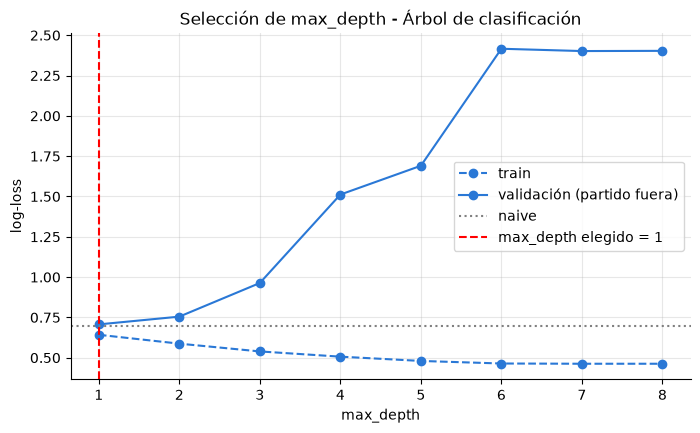

,log_loss_train,log_loss_validacion,AUC_validacion
max_depth,,,
1,0.642,0.707,0.481
2,0.587,0.755,0.513
3,0.539,0.963,0.480
4,0.507,1.512,0.481
5,0.480,1.690,0.531
6,0.464,2.416,0.522
7,0.463,2.402,0.524
8,0.463,2.403,0.524


In [44]:
from sklearn.metrics import log_loss
from sklearn.tree import DecisionTreeClassifier, plot_tree

filas = []
for prof in range(1, 9):
    arbol_tmp = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=10, random_state=datos.SEMILLA)
    p_val = mod.predecir_cv(arbol_tmp, X_train, y_train, pliegues)
    p_tr = mod.con_imputacion(arbol_tmp).fit(X_train, y_train).predict_proba(X_train)[:, 1]
    filas.append({'max_depth': prof, 'log_loss_train': log_loss(y_train, p_tr),
                  'log_loss_validacion': log_loss(y_train, p_val), 'AUC_validacion': mod.metricas(y_train, p_val, pliegues)['AUC']})
curva_arbol = pd.DataFrame(filas).set_index('max_depth')
PROF = curva_arbol['log_loss_validacion'].idxmin()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curva_arbol.index, curva_arbol['log_loss_train'], 'o--', color='#2a78d6', label='train')
ax.plot(curva_arbol.index, curva_arbol['log_loss_validacion'], 'o-', color='#2a78d6', label='validación (partido fuera)')
ax.axhline(resultados_cv['naive']['log_loss'], color='gray', linestyle=':', label='naive')
ax.axvline(PROF, color='red', linestyle='--', label=f'max_depth elegido = {PROF}')
ax.set(xlabel='max_depth', ylabel='log-loss', title='Selección de max_depth - Árbol de clasificación')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
plt.show()
curva_arbol.round(3)

,importancia
dif_suma_nivel_padel,1.0


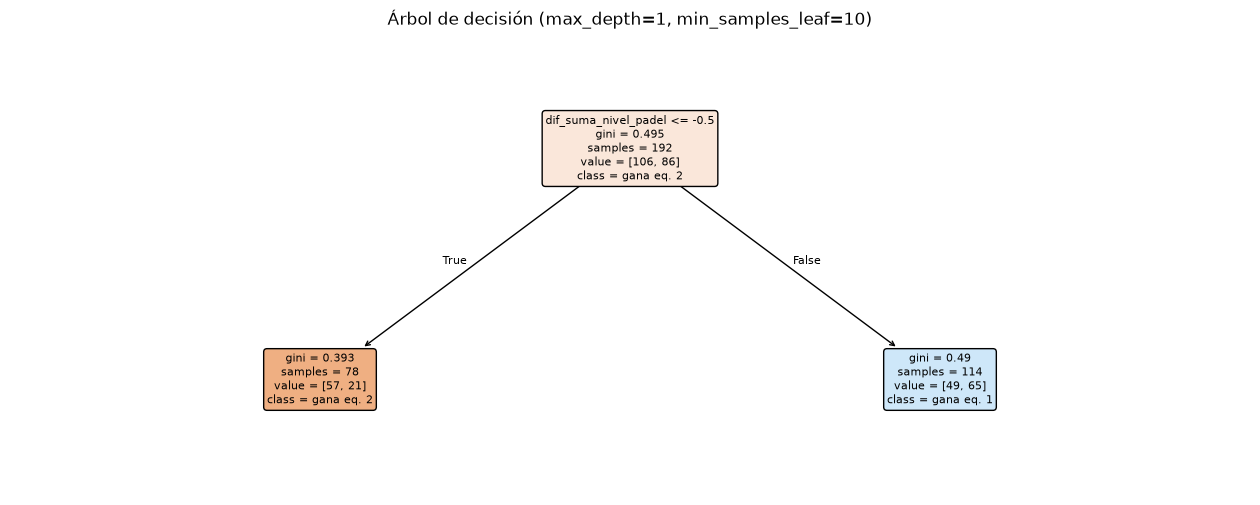

In [45]:
arbol = DecisionTreeClassifier(max_depth=PROF, min_samples_leaf=10, random_state=datos.SEMILLA)
p_arbol = mod.predecir_cv(arbol, X_train, y_train, pliegues)
resultados_cv['arbol'] = mod.metricas(y_train, p_arbol, pliegues)

arbol_final = mod.con_imputacion(arbol).fit(X_train, y_train)[-1]
importancias = pd.Series(arbol_final.feature_importances_, index=var.VARIABLES_MODELO).sort_values(ascending=False)
display(importancias[importancias > 0].round(3).to_frame('importancia'))

plt.figure(figsize=(16, 6))
plot_tree(arbol_final, feature_names=var.VARIABLES_MODELO, class_names=['gana eq. 2', 'gana eq. 1'], filled=True, rounded=True, fontsize=8)
plt.title(f'Árbol de decisión (max_depth={PROF}, min_samples_leaf=10)')
plt.show()

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584


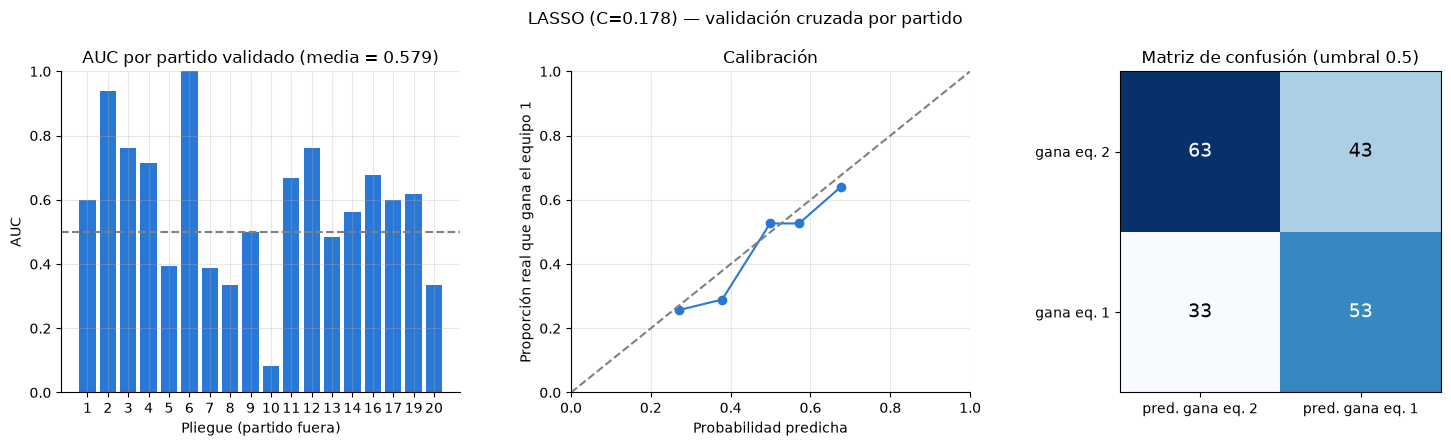

In [46]:
# Comparación de todos los modelos de la primera mitad de la fase 2 (validación cruzada por partido)
comparacion = pd.DataFrame(resultados_cv).T
display(comparacion.round(3))
mod.graficar_evaluacion(y_train, p_lasso, f"LASSO (C={mejor_C.loc['LASSO', 'C']:.3f}) — validación cruzada por partido", pliegues)

**Resultado**

Castigar los coeficientes si funciona. LASSO con C=0,178 baja el log-loss a 0,651 y el Brier a 0,229, y Ridge con C=0,018 queda casi igual con 0,655 y 0,231, los dos por debajo del naive de 0,696 y 0,251, entonces ya hay algo que el modelo aprende de las variables y que se sostiene en partidos que no vio. El AUC sube a 0,579 en LASSO pero con desviacion de 0,225 entre partidos, hay pliegues de 0,08 y otros de 1,0, con 6 a 13 puntos por partido el AUC de cada uno es muy ruidoso.

LASSO se queda con 7 de las 19 variables, no con 10 a 15 como decia la meta del D27. Las dos de arriba son las mismas que salieron significativas en la 2.3, dif_suma_nivel_padel y dif_suma_pct_quieto, despues vienen imc, el desbalance de nivel, velocidad p90, la diferencia de profundidad entre compañeros y prof_sd con coeficientes ya chiquitos. Del estilo puro, atacante y absdif_atacante, LASSO no deja nada. Eso no quiere decir que el estilo no importe, quiere decir que con 192 puntos no alcanza a separarse del ruido. Hay que decidir con el equipo si se fuerza a 10, se quedan las 7 o se usa Ridge que deja las 19 con pesos chicos, para la fase 4 Ridge tiene la ventaja de que el estilo sigue entrando.

El arbol sale mal. La mejor profundidad es 1, una sola pregunta sobre dif_suma_nivel_padel, y aun asi su log-loss de 0,707 queda peor que el naive, y con mas profundidad el train mejora y la validacion se dispara hasta 2,4, sobreajuste de libro. Con tan pocos puntos un arbol solo no sirve, a ver si el random forest y el boosting de la segunda mitad lo arreglan promediando muchos arboles ?

## 2.5 Random Forest, SVM y hyperparameter tuning — *pendiente*

**Objetivo:** probar los modelos avanzados con hiperparámetros elegidos por validación cruzada.

**Qué va en esta sección**
- **Random Forest:** número de árboles, profundidad y tamaño mínimo de hoja.
- **SVM:** kernel, C y gamma; las probabilidades se calibran.
- **Tuning:** Grid Search y Random Search (y Bayesiana si aplica) sobre los pliegues de la 2.1, nunca con `StratifiedKFold` al azar.

**Referencia:** `05_Hyperparameter_tunning.ipynb`, `RandomForest.ipynb` y `SVM 1.ipynb`.

## 2.6 Bagging y boosting — *pendiente*

**Objetivo:** probar los ensambles de árboles vistos en clase.

**Qué va en esta sección**
- **Bagging** de árboles de decisión, con el error *out-of-bag* y la importancia de variables.
- **Boosting:** AdaBoost y Gradient Boosting (XGBoost si se instala), con árboles poco profundos y learning rate bajo, porque con 244 puntos se sobreajustan fácil.
- **Red neuronal (opcional):** una red pequeña como comparación.

**Referencia:** `06_Bagging.ipynb` y `07_Boosting_Xgboost_v3.ipynb`.

## 2.7 Ensamblaje de modelos — *pendiente*

**Objetivo:** combinar los mejores modelos en uno solo.

**Qué va en esta sección**
- Voto por promedio de probabilidades (*soft voting*) de los mejores modelos de la 2.3 a la 2.6, como en la parte 4 del 06.
- Comparación del ensamblaje contra cada modelo por separado.

**Referencia:** `06_Bagging.ipynb` (parte 2: ensamblaje manual; parte 4: voto mayoritario).

## 2.8 Comparación final, bootstrap y modelo para la fase 4 — *pendiente*

**Objetivo:** elegir el modelo que pasa a la fase 4.

**Qué va en esta sección**
- Tabla con todas las métricas en el test (los 5 partidos que ningún modelo vio).
- **Bootstrap por partido:** intervalos de las métricas remuestreando partidos completos.
- Curva de calibración del modelo elegido y prueba de simetría (al intercambiar las parejas, p + p' ≈ 1).
- Decisión del modelo final y registro en el README.

**Referencia:** `06_Bagging.ipynb` (bootstrap) y métricas del `03_Regresion_Logistica.ipynb`.

# Fase 3 — Distribuciones — *pendiente*

- Una distribución empírica por variable aleatoria y por jugador. Los valores fijos (estatura, peso, nivel) entran como atributos y no se modelan como distribución.
- Se compara el bootstrap empírico contra una distribución paramétrica ajustada, teniendo en cuenta las pocas observaciones por jugador.

### Nota para el equipo: qué hereda la fase 3 de la 1.11
- **Las 19 variables (D34) se arman desde cada jugador** con `var.combinar_pareja` (error 0 en los 244 puntos). La fase 3 tiene que entregar, por jugador, los valores con los que se arman: `atacante`, `prof_media_m`, `prof_sd_m`, `pct_en_su_lado`, `vel_p90`, `area_m2`, `pct_quieto`, `rafagas_por_min` y las fijas de `jugadores`.
- **Pregunta abierta:** ¿los valores de cada jugador se sortean por separado o por punto completo? En un punto real los dos compañeros y el rival juegan a la vez, así que sortearlos por separado podría romper esa relación. Se decide con el equipo antes de empezar.
- **`atacante` es 0 o 1 en cada punto:** la distribución de cada jugador es la proporción de sus puntos en que fue atacante.
- **Las fijas no se sortean:** estatura, IMC, nivel, tiempo jugando, otra raqueta, frecuencia de deporte y género son atributos del jugador.

# Fase 4 — Simulación — *pendiente*

- Se simulan combinaciones de parejas y partidos muestreando las distribuciones de la fase 3 y evaluándolas con el modelo de la fase 2.
- Resultado esperado: un ranking de parejas por probabilidad media de ganar contra el resto, con intervalos de incertidumbre.

### Nota para el equipo: qué hereda la fase 4 de la 1.11 y de la fase 2
- **Armar un partido simulado:** se sortean los valores de los 4 jugadores (fase 3), se arma cada pareja con `var.combinar_pareja`, se calcula la `dif_` (pareja 1 − pareja 2) y el modelo final de la fase 2 da p(gana el punto la pareja 1).
- **`pct_en_su_lado` depende del lado asignado:** la simulación tiene que decidir quién juega drive (RIGHT) y quién revés (LEFT) en cada pareja.
- **Simetría:** al intercambiar las parejas, todas las `dif_` cambian de signo. Hay que revisar que p(A gana a B) + p(B gana a A) ≈ 1 con el modelo elegido.
- **Del punto al partido:** los partidos son a 7 puntos; la probabilidad de ganar el partido se obtiene simulando puntos hasta que una pareja llegue a 7.

---
<a id="anexo-a"></a>
# Anexo A — Registro de decisiones

El registro completo (D1 en adelante) es una sola tabla, en la sección **Registro de decisiones** del [README](../README.md#registro-de-decisiones). Cada sección de este notebook cita sus decisiones con su código `D#`.

# Anexo B — Supuestos y pendientes

La lista vigente está en la sección **Supuestos y pendientes** del [README](../README.md#supuestos-y-pendientes).

# Anexo C — Tablas derivadas

Diccionario de columnas: la parte B de [`docs/diccionario.md`](../docs/diccionario.md).

In [47]:
def leer_interim(f):
    return pd.read_parquet(f) if f.suffix == '.parquet' else pd.read_csv(f, encoding='utf-8-sig', low_memory=False)

display(pd.DataFrame([
    {'archivo': f'{f.parent.name}/{f.name}', 'filas': len(t := leer_interim(f)), 'columnas': t.shape[1],
     'MB': round(f.stat().st_size / 1e6, 1)}
    for f in sorted([*datos.DATA_INTERIM.glob('*.csv'), *datos.DATA_INTERIM.glob('*.parquet'), *datos.DATA_PROCESSED.glob('*.csv')])
]))

,archivo,filas,columnas,MB
0,interim/equivalencias_nombres.csv,89,5,0.0
1,interim/filtros_variables.csv,83,3,0.0
2,interim/identidades_video.csv,1201,21,0.2
3,interim/jugadores.csv,32,23,0.0
4,interim/parejas_punto.csv,244,247,0.5
5,interim/participaciones.csv,1132,44,0.3
6,interim/puntos.csv,287,29,0.0
7,interim/video_limpio.parquet,705888,42,78.1
8,processed/tabla_modelo.csv,244,164,0.3
